In [2]:
# import numpy as np
import pandas as pd
import matplotlib.gridspec as gridspec

import matplotlib.pyplot as plt
from matplotlib.backends.backend_agg import FigureCanvas
from scipy.spatial import distance
import random as rand
import pickle
from scipy import stats
import time


# allow us to re-use the framework from the src directory
import sys, os
sys.path.append(os.path.abspath(os.path.join('../')))

import max_ent.examples.grid_9_by_9 as G
from max_ent.utility.support import *
from max_ent.gridworld import Directions


rand.seed(123)
np.random.seed(123)

In [3]:

'''label='length'
list_df = [df3[label],df4[label]]
list_mean=[(np.mean(x)+np.std(x))*1.1 for x in list_df]

print(np.max(list_mean))
'''
'''def min_max(label, df, df2, df3, df4, df7):
    list_df = [df[label],df2[label],df3[label],df4[label],df7[label]]
    list_mean=[(np.mean(x) + np.sign(np.mean(x)) * np.std(x))*1.1 for x in list_df]
    print(list_mean)
    min_label=np.min(list_mean)
    max_label=np.max(list_mean)
    
    if min_label < 0 and max_label < 0:
        max_label = 0
    elif min_label > 0 and max_label > 0:
        min_label = 0
    
    return min_label, max_label'''

def min_max(label, df):
    list_df = df[label]
    list_mean=[(np.mean(x) + np.sign(np.mean(x)) * np.std(x))*1.1 for x in list_df]
    #print(list_mean)
    min_label=np.min(list_mean)
    max_label=np.max(list_mean)
    
    if min_label < 0 and max_label < 0:
        max_label = 0
    elif min_label > 0 and max_label > 0:
        min_label = 0
    
    return min_label, max_label

In [4]:
def plot_subtype(x, y, df, hue, title, filename, min_label=0, max_label=None, list_threshold3= None, dropna = False):
    
    #print(f"{[min_label, max_label]}")
    sns.set(rc={'figure.figsize':(11.7,8.27)})
    sns.set_theme(style="whitegrid")
    sns.set(font_scale=2)
    sns.color_palette("viridis", as_cmap=True)
    
    fig = plt.figure(figsize=(30, 15))
    # grid for pairs of subplots
    rows = len(list_threshold3)
    cols = 5
    grid = plt.GridSpec(rows, cols)

    #figure, axis = plt.subplots(len(list_threshold3), 2, figsize=(25, 30))
    #plt.tight_layout()
    #print(axis)

    #for index, t3, sub_plot in enumerate(list_threshold3,axis):
    for i in range(rows):
        
        t3 = list_threshold3[i]
        # create fake subplot just to title set of subplots
        fake = fig.add_subplot(grid[i, :])
        # '\n' is important
        #fake.set_title(f'{title+str(t3)}\n', fontweight='semibold')
        fake.set_axis_off()
        
        # create subgrid for two subplots without space between them
        # <https://matplotlib.org/2.0.2/users/gridspec.html>
        gs = gridspec.GridSpecFromSubplotSpec(1, cols, subplot_spec=grid[i, :])

        # real subplot #1
        ax = fig.add_subplot(gs[0])
        ax.set_title(f'Det. = 0.0')
        temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==t3) & ((df['type']=='SOFAI w/ S1 ra=0.0') )  ] #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        plt.xlabel("Trajectories")
        plt.ylabel("Perc. of Use of S1 and S2")
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], errorbar=None,hue=hue,markers=True, dashes=False)
        plt.legend(labels=['S1', 'S2'])
        if max_label: g.set_ylim([min_label, max_label])
        #axis[0,0].set_title('Myopic')'''

        # real subplot #2
        ax = fig.add_subplot(gs[1], sharey=ax)
        ax.set_title(f'Det. = 0.25')
        temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==t3) &  ((df['type']=='SOFAI w/ S1 ra=0.25') )  ] #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        plt.xlabel("Trajectories")
        plt.ylabel(" ")
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], errorbar=None,hue=hue,markers=True, dashes=False)
        plt.legend(labels=['S1', 'S2'])
        if max_label: g.set_ylim([min_label, max_label])
        #axis[0,1].set_title('No Myopic')
        
        # real subplot #2
        ax = fig.add_subplot(gs[2], sharey=ax)
        ax.set_title(f'Det. = 0.5')
        temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==t3) &  ((df['type']=='SOFAI w/ S1 ra=0.5') )  ] #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        plt.xlabel("Trajectories")
        plt.ylabel(" ")
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], errorbar=None,hue=hue,markers=True, dashes=False)
        plt.legend(labels=['S1', 'S2'])
        if max_label: g.set_ylim([min_label, max_label])
            
        # real subplot #2
        ax = fig.add_subplot(gs[3], sharey=ax)
        ax.set_title(f'Det. = 0.75')
        temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==t3) &  ((df['type']=='SOFAI w/ S1 ra=0.75') ) ] #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        plt.xlabel("Trajectories")
        plt.ylabel(" ")
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], errorbar=None, hue=hue,markers=True, dashes=False)
        plt.legend(labels=['S1', 'S2'])
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], ci=None,hue=hue,markers=True, dashes=False, style=hue)
        if max_label: g.set_ylim([min_label, max_label])
            
        # real subplot #2
        ax = fig.add_subplot(gs[4], sharey=ax)
        ax.set_title(f'Det. = 1.0')
        temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==t3) &  ((df['type']=='SOFAI w/ S1 ra=1.0') ) ] #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        plt.xlabel("Trajectories")
        plt.ylabel(" ")
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], errorbar=None, hue=hue,markers=True, dashes=False)
        plt.legend(labels=['S1', 'S2'])
        #df_means = temp_df.groupby(x)[y].agg("mean").reset_index()
        #g = sns.scatterplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], hue=hue)
        #g = sns.scatterplot(ax=ax, x=x, y=y, data=df_means)
        if max_label: g.set_ylim([min_label, max_label])
        

    plt.savefig(filename+'.pdf')
    plt.show()

def plot_type(x, y, df, hue, title, filename, min_label=0, max_label=None, list_threshold3= None, dropna=False):
         
    ci=None
    #print(f"{[min_label, max_label]}")
    sns.set(rc={'figure.figsize':(11.7,8.27)})
    sns.set_theme(style="whitegrid")
    sns.set(font_scale=2)
    sns.color_palette("viridis", as_cmap=True)
    
    fig = plt.figure(figsize=(60, 30))
    # grid for pairs of subplots
    rows = len(list_threshold3)
    cols = 5
    grid = plt.GridSpec(rows, cols)
    #print(df['type'])

    #figure, axis = plt.subplots(len(list_threshold3), 2, figsize=(25, 30))
    #plt.tight_layout()
    #print(axis)

    #for index, t3, sub_plot in enumerate(list_threshold3,axis):
    for i in range(rows):
        
        t3 = list_threshold3[i]
        # create fake subplot just to title set of subplots
        fake = fig.add_subplot(grid[i, :])
        # '\n' is important
        fake.set_title(f'{title+str(t3)}\n', fontweight='semibold')
        fake.set_axis_off()
        
        # create subgrid for two subplots without space between them
        # <https://matplotlib.org/2.0.2/users/gridspec.html>
        gs = gridspec.GridSpecFromSubplotSpec(1, cols, subplot_spec=grid[i, :])

        # real subplot #1
        ax = fig.add_subplot(gs[0])
        ax.set_title(f'Det. = 0.0')
        temp_df = df.loc[(df['traj_n']>=0) & (((df['t3']==t3) & (df['type']=='SOFAI w/ S1 ra=0.0')) | (df['t3']==0))].dropna() #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=0.0'], hue=hue,markers=True, dashes=False, errorbar=None, )
        plt.legend(labels=['S2', 'SOFAI'])
        if max_label: g.set_ylim([min_label, max_label])
        #axis[0,0].set_title('Myopic')'''

        # real subplot #2
        ax = fig.add_subplot(gs[1], sharey=ax)
        ax.set_title(f'Det. = 0.25')
        temp_df = df.loc[(df['traj_n']>=0) & (((df['t3']==t3) & (df['type']=='SOFAI w/ S1 ra=0.25')) | (df['t3']==0))].dropna() #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=0.25'], hue=hue,markers=True, dashes=False,errorbar=None)
        plt.legend(labels=['S2', 'SOFAI'])
        if max_label: g.set_ylim([min_label, max_label])
            
        ax = fig.add_subplot(gs[2], sharey=ax)
        ax.set_title(f'Det. = 0.5')
        temp_df = df.loc[(df['traj_n']>=0) & (((df['t3']==t3) & (df['type']=='SOFAI w/ S1 ra=0.5')) | (df['t3']==0))].dropna() #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=0.5'], hue=hue,markers=True, errorbar=None, dashes=False)
        plt.legend(labels=['S2', 'SOFAI'])
        if max_label: g.set_ylim([min_label, max_label])
            
        ax = fig.add_subplot(gs[3], sharey=ax)
        ax.set_title(f'Det. = 0.75')
        temp_df = df.loc[(df['traj_n']>=0) & (((df['t3']==t3) & (df['type']=='SOFAI w/ S1 ra=0.75')) | (df['t3']==0))].dropna() #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=0.75'], hue=hue,markers=True, errorbar=None, dashes=False)
        plt.legend(labels=['S2', 'SOFAI'])
        if max_label: g.set_ylim([min_label, max_label])
            
        ax = fig.add_subplot(gs[4], sharey=ax)
        ax.set_title(f'Det. = 1.0')
        temp_df = df.loc[(df['traj_n']>=0) & (((df['t3']==t3) & (df['type']=='SOFAI w/ S1 ra=1.0')) | (df['t3']==0))].dropna() #| (df['type']=='s1_nb') 
        if dropna : temp_df = temp_df.dropna()
        g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=1.0'], hue=hue,markers=True, errorbar=None, dashes=False)
        plt.legend(labels=['S2', 'SOFAI'])
        #df_means = temp_df.groupby('type')[y].agg("mean").reset_index()
        #g = sns.scatterplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], hue=hue)
        #g = sns.scatterplot(ax=ax, y=y, data=df_means, size=10, hue=hue)
        if max_label: g.set_ylim([min_label, max_label])
        #axis[0,1].set_title('No Myopic')

    plt.savefig(filename+'.pdf')
    plt.show()



In [5]:
def f(count_stat):
    Z = []

    for x in range(9):
        temp_grid = []
        for y in range(9):
            #print(f"({x},{y})")
            temp_grid.append(np.sum(count_stat[0][y][8-x]))
            
        #print(temp_grid)
        Z.append(temp_grid)
    return np.array(Z)

In [6]:
def plot_results(df, x, y, min_label, max_label, bootstrap = 0):
    
    fig=plt.figure(figsize=(12, 7))
    sns.set(rc={'figure.figsize':(11.7,8.27)})
    sns.set_theme(style="whitegrid")
    sns.set(font_scale=2)
    sns.color_palette("viridis", as_cmap=True)
    temp_df = df.loc[(df['type']!="S1 noMyopic")&(df['type']!="const")&(df['type']!="nominal")& (df['type']!="S1 Myopic") & (df['type']!="S2")& (df['traj_n']>=bootstrap)]
    #print("Prima")
    #g=sns.lineplot(x=x, y=y, data=df, hue="type",markers=True, dashes=False)
    g = sns.barplot(x=x, y=y, hue="type", data=temp_df, palette="autumn", ci=95);
    #print("Dopo")
    #g.set_xticklabels([f"({(i)/10:0.1f}, {1 - (i)/10:0.1f})" for i in range(11)])
    
    constrained_line = np.mean(df.loc[(df['type']=="const")][y])
    nominal_line = np.mean(df.loc[(df['type']=="nominal")][y])
    #print(f"constrained_line: {constrained_line} {y}")
    #print(f"nominal_line: {nominal_line} {y}")
    #s1_line = np.mean(df.loc[(df['type']=="s1")& (df['traj_n']>=bootstrap)][y])
    s2_line = np.mean(df.loc[(df['type']=="S2")& (df['traj_n']>=0)][y])
    #mixed_line = np.median(temp_df.loc[(temp_df['type']=="mixed")& (temp_df['traj_n']>=bootstrap)][y])
    #s1nb_line_noMyopic = np.mean(df.loc[(df['type']=="S1 noMyopic")& (df['traj_n']>=0)][y])
    #s1nb_line_Myopic = np.mean(df.loc[(df['type']=="S1 Myopic")& (df['traj_n']>=0)][y])
    
    #print(f"s2: {s2_line} s1:{s1nb_line}")
    
    g.axhline(constrained_line, color='r', linestyle='--', label="RL Constrained")
    g.axhline(nominal_line, color='b', linestyle='--', label="RL Nominal")
    #g.axhline(s1_line, color='b', linestyle='--', label="S1")
    #g.axhline(mixed_line, color='g', linestyle='--', label="Mixed")
    #g.axhline(s1nb_line_noMyopic, color='b', linestyle='-.', label="S1 no Myopic")
    #g.axhline(s1nb_line_Myopic, color='black', linestyle='-.', label="S1 Myopic")
    g.axhline(s2_line, color='g', linestyle='-.', label="S2")
    #g.set_ylim([min_label, max_label])

    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    #plt.title(label=y+" varying "+x)
    
    '''h, l = g.get_legend_handles_labels()
    labels=["S1", "S2","SOFAI 10","SOFAI 01","SOFAI 02"]
    g.legend(h, labels)'''
    plt.legend()
    plt.grid(alpha=0.3)
    #g.set_xticks(range(11)) # <--- set the ticks first

    #plt.xlabel("W(Nominal, Constraints)")
    #plt.ylabel("Avg JS dist")
    plt.show()
    #fig.savefig(os.path.join("./", f"{y}_varying_{x}.png"), bbox_inches = 'tight')
    fig.savefig(os.path.join("./", f"{y}.pdf"), bbox_inches = 'tight')

In [31]:
def runSOFAI(n, c, mca_01_myopic, threshold1, threshold2, threshold3, threshold4, threshold5, ra, n_trajectories, trial, mca_s2, title, constraints, n_grid=None, only_s1=False):
    s1_ra0 = System1Solver(myopic=False, ra=ra)
    if mca_01_myopic is None: 
        if only_s1:
            mca_01_myopic = MCA(n=n, c=c, s1=s1_ra0, demo=None, threshold1=threshold1, threshold2=threshold2, threshold3 = threshold3, threshold4 = threshold4, threshold5=1, only_s1=only_s1)
        else:
            mca_01_myopic = MCA(n=n, c=c, s1=s1_ra0, s2=mca_s2.s2, demo=None, threshold1=threshold1, threshold2=threshold2, threshold3 = threshold3, threshold4 = threshold4, threshold5=1, only_s1=only_s1)
    else:
        mca_01_myopic.setGrid(grid=n, constraints=c)  
        
    demo_mca_01_myopic = mca_01_myopic.generate_trajectories(n_trajectories, discard_not_feasable=False)
    #temp_matrix_mca_01_myopic = count_states(demo_mca_01_myopic.trajectories, c_cfg.mdp, n, constraints, bootstrap = bootstrap)
    temp_dict=build_dict(type_mca=title, agent=mca_01_myopic, t3= threshold3, demo = demo_mca_01_myopic, constraints= constraints, trial = trial, n_grid = n_grid, n_trajectories=n_trajectories)
    #f1 = G.plot_world(f'SOFAI_myopic', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_01_myopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
    #df = pd.concat([df, temp_dict])

    temp_jsdiv = {}
    temp_jsdiv['t3'] = threshold3
    temp_jsdiv['t4'] = threshold4
    if mca_s2: temp_jsdiv['jsdiv'] = js_divergence((mca_s2.modelSelf.ntra_per_transition + 1E-10)/np.sum(mca_s2.modelSelf.ntra_per_transition + 1E-10), (mca_01_myopic.modelSelf.ntra_per_transition + 1E-10)/np.sum(mca_01_myopic.modelSelf.ntra_per_transition + 1E-10))
    temp_jsdiv['type'] = title
    temp_jsdiv = pd.DataFrame(data=temp_jsdiv, index=[0])
    
    return mca_01_myopic, temp_dict, temp_jsdiv, demo_mca_01_myopic

In [7]:
n_grids = 10

n_trials = 500 #

n_trajectories = 1
goal = 40

bootstrap = 0
n_constraints = 27
n_actions = 4

threshold1 = 0 # 
threshold2 = 0.95 #0.95 # THIS REMOVE SECOND CONDITION
#threshold3 = 0.1
#list_threshold3 = [0.1, 0.3, 0.6, 0.9] # try with 0.9 or 1.0 / myopic and non-myopic S1
list_threshold3 = [0,1] # try with 0.9 or 1.0 / myopic and non-myopic S1
threshold4 = 0 # 

p_slip = 0.1

In [33]:

df = pd.DataFrame()
df2 = pd.DataFrame()
df3 = pd.DataFrame()
df4 = pd.DataFrame()
df7 = pd.DataFrame()

In [9]:

time_tot = int(round(time.time() * 1000))

df = pd.DataFrame()
js_div = pd.DataFrame()
mca = []
size = 9

mca_1 = None
mca_2 = None
mca_3 = None
mca_4 = None
mca_5 = None

list_initial_state = [0,1,2,3,4,5,6,7,8,9,18,27,36,45,54,63,72,73,74,75,76,77,78,79,80,17,26,35,44,53,62,71]

for n_grid in range(n_grids):

    
    temp_df_to_clean = pd.DataFrame()
    resetModelSelf = True
    mca_agents = [None for i in range(20)]

    #generate random constraints
    blue, green, cs, ca, start, goal = generate_constraints(9, n_constraints=n_constraints,goal = goal, action=n_actions)
    constraints = {'blue': blue, 'green': green, 'cs':cs, 'ca':ca}

    
    #list_available = [x for x in range(size ** 2)]
    list_available = np.array(list_initial_state)
    list_available = np.setdiff1d(list_available, blue)
    list_available = np.setdiff1d(list_available, green)
    list_available = np.setdiff1d(list_available, cs)
    list_available = np.setdiff1d(list_available, [goal])
    
    start = np.random.choice(np.setdiff1d(list_initial_state, cs))

    demo_list =[]
    
    #generate nomminal 
    time_exp = int(round(time.time() * 1000))
    n, n_cfg, demo_n, f1 = create_world('Nominal', blue, green, start=start, goal=goal, n_trajectories=200, p_slip=p_slip, draw=False)
    time_exp = int(round(time.time() * 1000)) - time_exp 
    temp_matrix = count_states(demo_n.trajectories, n_cfg.mdp, n, constraints)
    '''temp_dict=build_dict(temp_matrix, type_mca='nominal')
    temp_dict['time'] = time_exp / n_trajectories
    df = pd.concat([df, temp_dict])'''

    '''Z_distr = f(temp_matrix)
    Z_distr = np.array(Z_distr)
    Z_distr = Z_distr + 1E-3
    Z_distr[8-int(start/9)][int(start%9)]=0
    Z_distr[8-int(goal/9)][int(goal%9)] = 0

    #plt.imshow(Z_distr/np.sum(Z_distr), cmap='hot', interpolation='nearest')
    #plt.show()

    #Z_distr/np.sum(Z_distr)
    distr = np.array(Z_distr/np.sum(Z_distr))

    new_distr = []
    for idistr in range(len(distr)):
        new_distr.append(distr[len(distr)-idistr-1])

    new_distr = np.array(new_distr)'''


    ##cs = np.random.choice(np.arange(0,81), replace=False, p = new_distr.flatten(), size = n_constraints)
    #constraints = {'blue': blue, 'green': green, 'cs':cs, 'ca':ca}
    print(f"Start: {start} Goal: {goal} \nConstraints: {constraints}")
    #exit()

    #generate constrained grid
    cc = [1, 2]
    time_exp = int(round(time.time() * 1000))
    c, c_cfg, demo_c, f2 = create_world('Constrained', blue, green, cs, ca, cc, start=start, goal=goal, check=True, n_trajectories=200, p_slip=p_slip, draw=False)
    time_exp = int(round(time.time() * 1000)) - time_exp 

    #COMPUTE STATISTICS FOR NOMINAL
    temp_matrix = count_states(demo_n.trajectories, c_cfg.mdp, n, constraints)
    temp_dict=build_dict(temp_matrix, type_mca='nominal', demo = demo_n, constraints= constraints, trial = 0, n_grid = n_grid)
    temp_dict['time'] = time_exp / n_trajectories
    ###df = pd.concat([df, temp_dict])

    #COMPUTE STATISTICS FOR CONSTRAINED
    temp_matrix = count_states(demo_c.trajectories, c_cfg.mdp, n, constraints)
    temp_dict=build_dict(temp_matrix, type_mca='const', demo = demo_c, constraints= constraints, trial = 0, n_grid = n_grid)
    temp_dict['time'] = time_exp / n_trajectories
    ###df = pd.concat([df, temp_dict])

    for trial in range(n_trials):
        #print(f"Iteration {trial}")
        #generate constraints

        #start = np.random.choice(list_available)
        #start = np.random.choice(list_initial_state)
        '''generate = True
        while generate:
            # generate start state from the list of non-constrained states
            start = np.random.choice(list_available)
            start_x = start % size
            start_y = start // size

            goal_x = goal % size
            goal_y = goal // size

            if abs(start_x-goal_x) > 3 or abs(start_y-goal_y) > 3:
                generate = False'''

        '''blue = [21,  9, 59,  1,  0, 20]
        green = [42, 18, 76, 41, 23, 30]
        cs = [63, 74, 13, 39, 48, 38]
        ca = [Directions.DOWN_LEFT, Directions.UP_LEFT]'''
        ##start =7
        ##goal = 65
        
        if resetModelSelf: 
            mca_s2 = MCA(n=n, c=c, demo=None, threshold5=1, only_s2=True)
        else:
            mca_s2.setGrid(grid=n, constraints=c)

        demo_mca_s2 = mca_s2.generate_trajectories(n_trajectories)
        #temp_matrix_mca_s2 = count_states(demo_mca_s2.trajectories, c_cfg.mdp, n, constraints, bootstrap = bootstrap)
        temp_dict=build_dict( type_mca='S2', agent=mca_s2 , demo = demo_mca_s2, constraints= constraints, trial = trial, n_grid = n_grid, n_trajectories=n_trajectories)
        #f1 = G.plot_world(f'Only S2', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_s2, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
        #df = pd.concat([df, temp_dict])
        temp_df_to_clean = pd.concat([temp_df_to_clean, temp_dict])

        for i_threshold3 in range(len(list_threshold3)):

            print(f"\n ************** Threshold {i_threshold3}: Trial {trial} grid {n_grid} ******************")
            threshold3 = list_threshold3[i_threshold3]

            '''mca_agents[i_threshold3 * 5 + 0], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold3 * 5 + 0], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=0.0', constraints= constraints)
            df = pd.concat([df, temp_dict])
            js_div = pd.concat([js_div, temp_jsdiv])

            mca_agents[i_threshold3 * 5 + 1], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold3 * 5 + 1], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0.25, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=0.25', constraints= constraints)
            df = pd.concat([df, temp_dict])
            js_div = pd.concat([js_div, temp_jsdiv])

            mca_agents[i_threshold3 * 5 + 2], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold3 * 5 + 2], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0.5, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=0.5', constraints= constraints)
            df = pd.concat([df, temp_dict])
            js_div = pd.concat([js_div, temp_jsdiv])

            mca_agents[i_threshold3 * 5 + 3], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold3 * 5 + 3], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0.75, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=0.75', constraints= constraints)
            df = pd.concat([df, temp_dict])
            js_div = pd.concat([js_div, temp_jsdiv])'''

            mca_agents[i_threshold3 * 5 + 4], temp_dict, temp_jsdiv, demo = runSOFAI(n, c, mca_agents[i_threshold3 * 5 + 4], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 1, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = mca_s2, title = 'SOFAI w/ S1 ra=1.0', constraints= constraints)
            if i_threshold3 == len(list_threshold3)-1: demo_list = demo_list + demo.trajectories
            #df = pd.concat([df, temp_dict])
            #js_div = pd.concat([js_div, temp_jsdiv])
            temp_df_to_clean = pd.concat([temp_df_to_clean, temp_dict])

            if ((trial+1) %25 ==0): 
                '''r=mca_agents[i_threshold3 * 5 + 0].reflect(p=0.2, verbose=False)
                r=mca_agents[i_threshold3 * 5 + 1].reflect(p=0.2, verbose=False)
                r=mca_agents[i_threshold3 * 5 + 2].reflect(p=0.2, verbose=False)
                r=mca_agents[i_threshold3 * 5 + 3].reflect(p=0.2, verbose=False)'''
                r=mca_agents[i_threshold3 * 5 + 4].reflect(p=0.2, verbose=False)
                print(f"Temperature: {mca_agents[i_threshold3 * 5 + 4].temperature}")

            resetModelSelf = False

        time_exp = int(round(time.time() * 1000))
    df = pd.concat([df, temp_df_to_clean])


'''f1 = G.plot_world(f'Only S1', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_s1_nb_noMyopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
#f1 = G.plot_world(f'Only S1', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_s1_nb_Myopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
f1 = G.plot_world(f'Only S2', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_s2, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
f1 = G.plot_world(f'SOFAI_myopic', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_01_myopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
f1 = G.plot_world(f'SOFAI_noMyopic', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_01_noMyopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
'''
time_tot = int(round(time.time() * 1000)) - time_tot
print(f"Total time: {time_tot}")


[0.9625 0.0625 0.0625 0.9625 0.9625 0.0625 0.9625 0.9625]
Start: 27 Goal: 40 
Constraints: {'blue': [], 'green': [], 'cs': array([65, 59, 60,  4, 70, 54, 31, 78,  8, 44,  9, 37, 76, 29, 73, 80, 63,
       79, 45, 23,  1, 24, 66, 46, 61, 20, 14]), 'ca': [DOWN_LEFT, UP_RIGHT, LEFT, UP_LEFT]}
[0.9625 0.0625 0.0625 0.9625 0.9625 0.0625 0.9625 0.9625]

 ************** Threshold 0: Trial 0 grid 0 ******************

 ************** Threshold 1: Trial 0 grid 0 ******************

 ************** Threshold 0: Trial 1 grid 0 ******************

 ************** Threshold 1: Trial 1 grid 0 ******************

 ************** Threshold 0: Trial 2 grid 0 ******************

 ************** Threshold 1: Trial 2 grid 0 ******************

 ************** Threshold 0: Trial 3 grid 0 ******************

 ************** Threshold 1: Trial 3 grid 0 ******************

 ************** Threshold 0: Trial 4 grid 0 ******************

 ************** Threshold 1: Trial 4 grid 0 ******************

 *********


 ************** Threshold 0: Trial 60 grid 0 ******************

 ************** Threshold 1: Trial 60 grid 0 ******************

 ************** Threshold 0: Trial 61 grid 0 ******************

 ************** Threshold 1: Trial 61 grid 0 ******************

 ************** Threshold 0: Trial 62 grid 0 ******************

 ************** Threshold 1: Trial 62 grid 0 ******************

 ************** Threshold 0: Trial 63 grid 0 ******************

 ************** Threshold 1: Trial 63 grid 0 ******************

 ************** Threshold 0: Trial 64 grid 0 ******************

 ************** Threshold 1: Trial 64 grid 0 ******************

 ************** Threshold 0: Trial 65 grid 0 ******************

 ************** Threshold 1: Trial 65 grid 0 ******************

 ************** Threshold 0: Trial 66 grid 0 ******************

 ************** Threshold 1: Trial 66 grid 0 ******************

 ************** Threshold 0: Trial 67 grid 0 ******************

 ************** Threshol


 ************** Threshold 0: Trial 112 grid 0 ******************

 ************** Threshold 1: Trial 112 grid 0 ******************

 ************** Threshold 0: Trial 113 grid 0 ******************

 ************** Threshold 1: Trial 113 grid 0 ******************

 ************** Threshold 0: Trial 114 grid 0 ******************

 ************** Threshold 1: Trial 114 grid 0 ******************

 ************** Threshold 0: Trial 115 grid 0 ******************

 ************** Threshold 1: Trial 115 grid 0 ******************

 ************** Threshold 0: Trial 116 grid 0 ******************

 ************** Threshold 1: Trial 116 grid 0 ******************

 ************** Threshold 0: Trial 117 grid 0 ******************

 ************** Threshold 1: Trial 117 grid 0 ******************

 ************** Threshold 0: Trial 118 grid 0 ******************

 ************** Threshold 1: Trial 118 grid 0 ******************

 ************** Threshold 0: Trial 119 grid 0 ******************

 ********


 ************** Threshold 0: Trial 157 grid 0 ******************

 ************** Threshold 1: Trial 157 grid 0 ******************

 ************** Threshold 0: Trial 158 grid 0 ******************

 ************** Threshold 1: Trial 158 grid 0 ******************

 ************** Threshold 0: Trial 159 grid 0 ******************

 ************** Threshold 1: Trial 159 grid 0 ******************

 ************** Threshold 0: Trial 160 grid 0 ******************

 ************** Threshold 1: Trial 160 grid 0 ******************

 ************** Threshold 0: Trial 161 grid 0 ******************

 ************** Threshold 1: Trial 161 grid 0 ******************

 ************** Threshold 0: Trial 162 grid 0 ******************

 ************** Threshold 1: Trial 162 grid 0 ******************

 ************** Threshold 0: Trial 163 grid 0 ******************

 ************** Threshold 1: Trial 163 grid 0 ******************

 ************** Threshold 0: Trial 164 grid 0 ******************

 ********


 ************** Threshold 0: Trial 208 grid 0 ******************

 ************** Threshold 1: Trial 208 grid 0 ******************

 ************** Threshold 0: Trial 209 grid 0 ******************

 ************** Threshold 1: Trial 209 grid 0 ******************

 ************** Threshold 0: Trial 210 grid 0 ******************

 ************** Threshold 1: Trial 210 grid 0 ******************

 ************** Threshold 0: Trial 211 grid 0 ******************

 ************** Threshold 1: Trial 211 grid 0 ******************

 ************** Threshold 0: Trial 212 grid 0 ******************

 ************** Threshold 1: Trial 212 grid 0 ******************

 ************** Threshold 0: Trial 213 grid 0 ******************

 ************** Threshold 1: Trial 213 grid 0 ******************

 ************** Threshold 0: Trial 214 grid 0 ******************

 ************** Threshold 1: Trial 214 grid 0 ******************

 ************** Threshold 0: Trial 215 grid 0 ******************

 ********

...

Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Failed to improve, keeping the original trajectory
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too lo

Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory t

Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory t

Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Warning trajectory too long
Temperature: 0

 ************** Threshold 0: Trial 450 grid 4 ******************

 ************** Threshold 1: Trial 450 grid 4 ******************

 ************** Threshold 0: Trial 451 grid 4 ******************

 ************** Threshold 1: Trial 451 grid 4 ******************

 ************** Threshold 0: Trial 452 grid 4 **

Warning trajectory too long
Warning trajectory too long
Temperature: 0

 ************** Threshold 0: Trial 475 grid 4 ******************

 ************** Threshold 1: Trial 475 grid 4 ******************

 ************** Threshold 0: Trial 476 grid 4 ******************

 ************** Threshold 1: Trial 476 grid 4 ******************

 ************** Threshold 0: Trial 477 grid 4 ******************

 ************** Threshold 1: Trial 477 grid 4 ******************

 ************** Threshold 0: Trial 478 grid 4 ******************

 ************** Threshold 1: Trial 478 grid 4 ******************

 ************** Threshold 0: Trial 479 grid 4 ******************

 ************** Threshold 1: Trial 479 grid 4 ******************

 ************** Threshold 0: Trial 480 grid 4 ******************

 ************** Threshold 1: Trial 480 grid 4 ******************

 ************** Threshold 0: Trial 481 grid 4 ******************

 ************** Threshold 1: Trial 481 grid 4 ******************

 ***

In [34]:

time_tot = int(round(time.time() * 1000))

df = pd.DataFrame()
js_div = pd.DataFrame()
mca = []
size = 9

mca_1 = None
mca_2 = None
mca_3 = None
mca_4 = None
mca_5 = None

list_initial_state = [0,1,2,3,4,5,6,7,8,9,18,27,36,45,54,63,72,73,74,75,76,77,78,79,80,17,26,35,44,53,62,71]

for n_grid in range(n_grids):

    
    temp_df_to_clean = pd.DataFrame()
    resetModelSelf = True
    mca_agents = [None for i in range(20)]

    #generate random constraints
    blue, green, cs, ca, start, goal = generate_constraints(9, n_constraints=n_constraints,goal = goal, action=n_actions)
    constraints = {'blue': blue, 'green': green, 'cs':cs, 'ca':ca}

    
    #list_available = [x for x in range(size ** 2)]
    list_available = np.array(list_initial_state)
    list_available = np.setdiff1d(list_available, blue)
    list_available = np.setdiff1d(list_available, green)
    list_available = np.setdiff1d(list_available, cs)
    list_available = np.setdiff1d(list_available, [goal])
    
    start = np.random.choice(np.setdiff1d(list_initial_state, cs))

    demo_list =[]
    
    #generate nomminal 
    time_exp = int(round(time.time() * 1000))
    n, n_cfg, demo_n, f1 = create_world('Nominal', blue, green, start=start, goal=goal, n_trajectories=200, p_slip=p_slip, draw=False)
    time_exp = int(round(time.time() * 1000)) - time_exp 
    temp_matrix = count_states(demo_n.trajectories, n_cfg.mdp, n, constraints)
    '''temp_dict=build_dict(temp_matrix, type_mca='nominal')
    temp_dict['time'] = time_exp / n_trajectories
    df = pd.concat([df, temp_dict])'''

    '''Z_distr = f(temp_matrix)
    Z_distr = np.array(Z_distr)
    Z_distr = Z_distr + 1E-3
    Z_distr[8-int(start/9)][int(start%9)]=0
    Z_distr[8-int(goal/9)][int(goal%9)] = 0

    #plt.imshow(Z_distr/np.sum(Z_distr), cmap='hot', interpolation='nearest')
    #plt.show()

    #Z_distr/np.sum(Z_distr)
    distr = np.array(Z_distr/np.sum(Z_distr))

    new_distr = []
    for idistr in range(len(distr)):
        new_distr.append(distr[len(distr)-idistr-1])

    new_distr = np.array(new_distr)'''


    ##cs = np.random.choice(np.arange(0,81), replace=False, p = new_distr.flatten(), size = n_constraints)
    #constraints = {'blue': blue, 'green': green, 'cs':cs, 'ca':ca}
    print(f"Start: {start} Goal: {goal} \nConstraints: {constraints}")
    #exit()

    #generate constrained grid
    cc = [1, 2]
    time_exp = int(round(time.time() * 1000))
    c, c_cfg, demo_c, f2 = create_world('Constrained', blue, green, cs, ca, cc, start=start, goal=goal, check=True, n_trajectories=200, p_slip=p_slip, draw=False)
    time_exp = int(round(time.time() * 1000)) - time_exp 

    #COMPUTE STATISTICS FOR NOMINAL
    temp_matrix = count_states(demo_n.trajectories, c_cfg.mdp, n, constraints)
    temp_dict=build_dict(temp_matrix, type_mca='nominal', demo = demo_n, constraints= constraints, trial = 0, n_grid = n_grid)
    temp_dict['time'] = time_exp / n_trajectories
    ###df = pd.concat([df, temp_dict])

    #COMPUTE STATISTICS FOR CONSTRAINED
    temp_matrix = count_states(demo_c.trajectories, c_cfg.mdp, n, constraints)
    temp_dict=build_dict(temp_matrix, type_mca='const', demo = demo_c, constraints= constraints, trial = 0, n_grid = n_grid)
    temp_dict['time'] = time_exp / n_trajectories
    ###df = pd.concat([df, temp_dict])

    for trial in range(n_trials):
        #print(f"Iteration {trial}")
        #generate constraints

        #start = np.random.choice(list_available)
        #start = np.random.choice(list_initial_state)
        '''generate = True
        while generate:
            # generate start state from the list of non-constrained states
            start = np.random.choice(list_available)
            start_x = start % size
            start_y = start // size

            goal_x = goal % size
            goal_y = goal // size

            if abs(start_x-goal_x) > 3 or abs(start_y-goal_y) > 3:
                generate = False'''

        '''blue = [21,  9, 59,  1,  0, 20]
        green = [42, 18, 76, 41, 23, 30]
        cs = [63, 74, 13, 39, 48, 38]
        ca = [Directions.DOWN_LEFT, Directions.UP_LEFT]'''
        ##start =7
        ##goal = 65


        '''if resetModelSelf: 
            mca_s2 = MCA(n=n, c=c, demo=None, threshold5=1, only_s2=True)
        else:
            mca_s2.setGrid(grid=n, constraints=c)

        demo_mca_s2 = mca_s2.generate_trajectories(n_trajectories)
        #temp_matrix_mca_s2 = count_states(demo_mca_s2.trajectories, c_cfg.mdp, n, constraints, bootstrap = bootstrap)
        temp_dict=build_dict( type_mca='S2', agent=mca_s2 , demo = demo_mca_s2, constraints= constraints, trial = trial, n_grid = n_grid, n_trajectories=n_trajectories)
        #f1 = G.plot_world(f'Only S2', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_s2, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
        #df = pd.concat([df, temp_dict])
        temp_df_to_clean = pd.concat([temp_df_to_clean, temp_dict])'''
        
        
        for i_threshold3 in range(len(list_threshold3)):

            print(f"\n ************** Threshold {i_threshold3}: Trial {trial} grid {n_grid} ******************")
            threshold3 = list_threshold3[i_threshold3]

            mca_agents[i_threshold3 * 5 + 0], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold3 * 5 + 0], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = None, title = 'SOFAI w/ S1 ra=0.0', constraints= constraints, only_s1=True)
            df = pd.concat([df, temp_dict])
            js_div = pd.concat([js_div, temp_jsdiv])

            mca_agents[i_threshold3 * 5 + 1], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold3 * 5 + 1], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0.25, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = None, title = 'SOFAI w/ S1 ra=0.25', constraints= constraints, only_s1=True)
            df = pd.concat([df, temp_dict])
            js_div = pd.concat([js_div, temp_jsdiv])

            mca_agents[i_threshold3 * 5 + 2], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold3 * 5 + 2], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0.5, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = None, title = 'SOFAI w/ S1 ra=0.5', constraints= constraints, only_s1=True)
            df = pd.concat([df, temp_dict])
            js_div = pd.concat([js_div, temp_jsdiv])

            mca_agents[i_threshold3 * 5 + 3], temp_dict, temp_jsdiv, _ = runSOFAI(n, c, mca_agents[i_threshold3 * 5 + 3], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 0.75, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = None, title = 'SOFAI w/ S1 ra=0.75', constraints= constraints, only_s1=True)
            df = pd.concat([df, temp_dict])
            js_div = pd.concat([js_div, temp_jsdiv])

            mca_agents[i_threshold3 * 5 + 4], temp_dict, temp_jsdiv, demo = runSOFAI(n, c, mca_agents[i_threshold3 * 5 + 4], threshold1, threshold2, threshold3, threshold4, threshold5 = 1, ra = 1, n_trajectories = n_trajectories, trial = trial, n_grid = n_grid, mca_s2 = None, title = 'SOFAI w/ S1 ra=1.0', constraints= constraints, only_s1=True)
            if i_threshold3 == len(list_threshold3)-1: demo_list = demo_list + demo.trajectories
            #df = pd.concat([df, temp_dict])
            #js_div = pd.concat([js_div, temp_jsdiv])
            temp_df_to_clean = pd.concat([temp_df_to_clean, temp_dict])


        time_exp = int(round(time.time() * 1000))
    df = pd.concat([df, temp_df_to_clean])


'''f1 = G.plot_world(f'Only S1', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_s1_nb_noMyopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
#f1 = G.plot_world(f'Only S1', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_s1_nb_Myopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
f1 = G.plot_world(f'Only S2', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_s2, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
f1 = G.plot_world(f'SOFAI_myopic', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_01_myopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
f1 = G.plot_world(f'SOFAI_noMyopic', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, demo_mca_01_noMyopic, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)
'''
time_tot = int(round(time.time() * 1000)) - time_tot
print(f"Total time: {time_tot}")


[0.9625 0.0625 0.0625 0.9625 0.9625 0.0625 0.9625 0.9625]
Start: 18 Goal: 40 
Constraints: {'blue': [], 'green': [], 'cs': array([ 7, 10, 51, 15, 64, 14, 12, 39, 70, 36, 16, 37, 66, 63, 57, 77, 48,
       76, 79, 11, 38, 21,  4, 46, 74,  9, 28]), 'ca': [DOWN, DOWN_LEFT, RIGHT, DOWN_RIGHT]}
[0.9625 0.0625 0.0625 0.9625 0.9625 0.0625 0.9625 0.9625]

 ************** Threshold 0: Trial 0 grid 0 ******************

 ************** Threshold 1: Trial 0 grid 0 ******************

 ************** Threshold 0: Trial 1 grid 0 ******************

 ************** Threshold 1: Trial 1 grid 0 ******************

 ************** Threshold 0: Trial 2 grid 0 ******************

 ************** Threshold 1: Trial 2 grid 0 ******************

 ************** Threshold 0: Trial 3 grid 0 ******************

 ************** Threshold 1: Trial 3 grid 0 ******************

 ************** Threshold 0: Trial 4 grid 0 ******************

 ************** Threshold 1: Trial 4 grid 0 ******************

 *********


 ************** Threshold 1: Trial 40 grid 0 ******************

 ************** Threshold 0: Trial 41 grid 0 ******************

 ************** Threshold 1: Trial 41 grid 0 ******************

 ************** Threshold 0: Trial 42 grid 0 ******************

 ************** Threshold 1: Trial 42 grid 0 ******************

 ************** Threshold 0: Trial 43 grid 0 ******************

 ************** Threshold 1: Trial 43 grid 0 ******************

 ************** Threshold 0: Trial 44 grid 0 ******************

 ************** Threshold 1: Trial 44 grid 0 ******************

 ************** Threshold 0: Trial 45 grid 0 ******************

 ************** Threshold 1: Trial 45 grid 0 ******************

 ************** Threshold 0: Trial 46 grid 0 ******************

 ************** Threshold 1: Trial 46 grid 0 ******************

 ************** Threshold 0: Trial 47 grid 0 ******************

 ************** Threshold 1: Trial 47 grid 0 ******************

 ************** Threshol


 ************** Threshold 1: Trial 106 grid 0 ******************

 ************** Threshold 0: Trial 107 grid 0 ******************

 ************** Threshold 1: Trial 107 grid 0 ******************

 ************** Threshold 0: Trial 108 grid 0 ******************

 ************** Threshold 1: Trial 108 grid 0 ******************

 ************** Threshold 0: Trial 109 grid 0 ******************

 ************** Threshold 1: Trial 109 grid 0 ******************

 ************** Threshold 0: Trial 110 grid 0 ******************

 ************** Threshold 1: Trial 110 grid 0 ******************

 ************** Threshold 0: Trial 111 grid 0 ******************

 ************** Threshold 1: Trial 111 grid 0 ******************

 ************** Threshold 0: Trial 112 grid 0 ******************

 ************** Threshold 1: Trial 112 grid 0 ******************

 ************** Threshold 0: Trial 113 grid 0 ******************

 ************** Threshold 1: Trial 113 grid 0 ******************

 ********


 ************** Threshold 1: Trial 172 grid 0 ******************

 ************** Threshold 0: Trial 173 grid 0 ******************

 ************** Threshold 1: Trial 173 grid 0 ******************

 ************** Threshold 0: Trial 174 grid 0 ******************

 ************** Threshold 1: Trial 174 grid 0 ******************

 ************** Threshold 0: Trial 175 grid 0 ******************

 ************** Threshold 1: Trial 175 grid 0 ******************

 ************** Threshold 0: Trial 176 grid 0 ******************

 ************** Threshold 1: Trial 176 grid 0 ******************

 ************** Threshold 0: Trial 177 grid 0 ******************

 ************** Threshold 1: Trial 177 grid 0 ******************

 ************** Threshold 0: Trial 178 grid 0 ******************

 ************** Threshold 1: Trial 178 grid 0 ******************

 ************** Threshold 0: Trial 179 grid 0 ******************

 ************** Threshold 1: Trial 179 grid 0 ******************

 ********


 ************** Threshold 0: Trial 238 grid 0 ******************

 ************** Threshold 1: Trial 238 grid 0 ******************

 ************** Threshold 0: Trial 239 grid 0 ******************

 ************** Threshold 1: Trial 239 grid 0 ******************

 ************** Threshold 0: Trial 240 grid 0 ******************

 ************** Threshold 1: Trial 240 grid 0 ******************

 ************** Threshold 0: Trial 241 grid 0 ******************

 ************** Threshold 1: Trial 241 grid 0 ******************

 ************** Threshold 0: Trial 242 grid 0 ******************

 ************** Threshold 1: Trial 242 grid 0 ******************

 ************** Threshold 0: Trial 243 grid 0 ******************

 ************** Threshold 1: Trial 243 grid 0 ******************

 ************** Threshold 0: Trial 244 grid 0 ******************

 ************** Threshold 1: Trial 244 grid 0 ******************

 ************** Threshold 0: Trial 245 grid 0 ******************

 ********

...


 ************** Threshold 0: Trial 217 grid 9 ******************

 ************** Threshold 1: Trial 217 grid 9 ******************

 ************** Threshold 0: Trial 218 grid 9 ******************

 ************** Threshold 1: Trial 218 grid 9 ******************

 ************** Threshold 0: Trial 219 grid 9 ******************

 ************** Threshold 1: Trial 219 grid 9 ******************

 ************** Threshold 0: Trial 220 grid 9 ******************

 ************** Threshold 1: Trial 220 grid 9 ******************

 ************** Threshold 0: Trial 221 grid 9 ******************

 ************** Threshold 1: Trial 221 grid 9 ******************

 ************** Threshold 0: Trial 222 grid 9 ******************

 ************** Threshold 1: Trial 222 grid 9 ******************

 ************** Threshold 0: Trial 223 grid 9 ******************

 ************** Threshold 1: Trial 223 grid 9 ******************

 ************** Threshold 0: Trial 224 grid 9 ******************

 ********


 ************** Threshold 0: Trial 282 grid 9 ******************

 ************** Threshold 1: Trial 282 grid 9 ******************

 ************** Threshold 0: Trial 283 grid 9 ******************

 ************** Threshold 1: Trial 283 grid 9 ******************

 ************** Threshold 0: Trial 284 grid 9 ******************

 ************** Threshold 1: Trial 284 grid 9 ******************

 ************** Threshold 0: Trial 285 grid 9 ******************

 ************** Threshold 1: Trial 285 grid 9 ******************

 ************** Threshold 0: Trial 286 grid 9 ******************

 ************** Threshold 1: Trial 286 grid 9 ******************

 ************** Threshold 0: Trial 287 grid 9 ******************

 ************** Threshold 1: Trial 287 grid 9 ******************

 ************** Threshold 0: Trial 288 grid 9 ******************

 ************** Threshold 1: Trial 288 grid 9 ******************

 ************** Threshold 0: Trial 289 grid 9 ******************

 ********


 ************** Threshold 0: Trial 345 grid 9 ******************

 ************** Threshold 1: Trial 345 grid 9 ******************

 ************** Threshold 0: Trial 346 grid 9 ******************

 ************** Threshold 1: Trial 346 grid 9 ******************

 ************** Threshold 0: Trial 347 grid 9 ******************

 ************** Threshold 1: Trial 347 grid 9 ******************

 ************** Threshold 0: Trial 348 grid 9 ******************

 ************** Threshold 1: Trial 348 grid 9 ******************

 ************** Threshold 0: Trial 349 grid 9 ******************

 ************** Threshold 1: Trial 349 grid 9 ******************

 ************** Threshold 0: Trial 350 grid 9 ******************

 ************** Threshold 1: Trial 350 grid 9 ******************

 ************** Threshold 0: Trial 351 grid 9 ******************

 ************** Threshold 1: Trial 351 grid 9 ******************

 ************** Threshold 0: Trial 352 grid 9 ******************

 ********


 ************** Threshold 1: Trial 409 grid 9 ******************

 ************** Threshold 0: Trial 410 grid 9 ******************

 ************** Threshold 1: Trial 410 grid 9 ******************

 ************** Threshold 0: Trial 411 grid 9 ******************

 ************** Threshold 1: Trial 411 grid 9 ******************

 ************** Threshold 0: Trial 412 grid 9 ******************

 ************** Threshold 1: Trial 412 grid 9 ******************

 ************** Threshold 0: Trial 413 grid 9 ******************

 ************** Threshold 1: Trial 413 grid 9 ******************

 ************** Threshold 0: Trial 414 grid 9 ******************

 ************** Threshold 1: Trial 414 grid 9 ******************

 ************** Threshold 0: Trial 415 grid 9 ******************

 ************** Threshold 1: Trial 415 grid 9 ******************

 ************** Threshold 0: Trial 416 grid 9 ******************

 ************** Threshold 1: Trial 416 grid 9 ******************

 ********


 ************** Threshold 1: Trial 474 grid 9 ******************

 ************** Threshold 0: Trial 475 grid 9 ******************

 ************** Threshold 1: Trial 475 grid 9 ******************

 ************** Threshold 0: Trial 476 grid 9 ******************

 ************** Threshold 1: Trial 476 grid 9 ******************

 ************** Threshold 0: Trial 477 grid 9 ******************

 ************** Threshold 1: Trial 477 grid 9 ******************

 ************** Threshold 0: Trial 478 grid 9 ******************

 ************** Threshold 1: Trial 478 grid 9 ******************

 ************** Threshold 0: Trial 479 grid 9 ******************

 ************** Threshold 1: Trial 479 grid 9 ******************

 ************** Threshold 0: Trial 480 grid 9 ******************

 ************** Threshold 1: Trial 480 grid 9 ******************

 ************** Threshold 0: Trial 481 grid 9 ******************

 ************** Threshold 1: Trial 481 grid 9 ******************

 ********

In [36]:
temp_demo = Demonstration(mca_agents[4].modelSelf.trajectories, demo.policy)
''''df.to_csv("dati_myopic_nomyopic"+"_risk_"+str(threshold3)+".csv")
js_div.to_csv("jsdiv_myopic_nomyopic"+"_risk_"+str(threshold3)+".csv")'''

'\'df.to_csv("dati_myopic_nomyopic"+"_risk_"+str(threshold3)+".csv")\njs_div.to_csv("jsdiv_myopic_nomyopic"+"_risk_"+str(threshold3)+".csv")'

In [44]:
temp_mca_s2 = MCA(n=n, c=c, demo=None, threshold5=1, only_s2=True)
temp_demo_mca_s2 = temp_mca_s2.generate_trajectories(1)

#mca_agents

{'vmin': -50, 'vmax': 10, 'cmap': <matplotlib.colors.LinearSegmentedColormap object at 0x126b8bc90>}


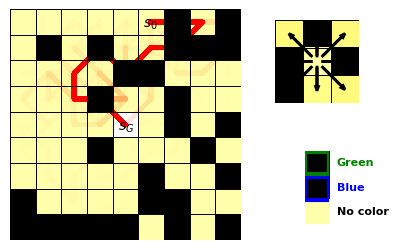

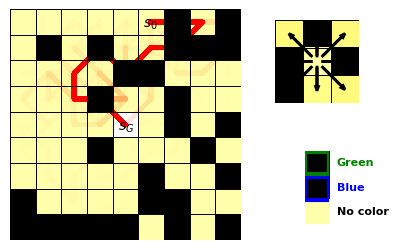

In [37]:
'''list_available = np.array(list_initial_state)
list_available = np.setdiff1d(list_available, blue)
list_available = np.setdiff1d(list_available, green)
list_available = np.setdiff1d(list_available, cs)
list_available = np.setdiff1d(list_available, [goal])

list_available'''
G.plot_world(f'Only S1', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, temp_demo, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)

{'vmin': -50, 'vmax': 10, 'cmap': <matplotlib.colors.LinearSegmentedColormap object at 0x14c769050>}


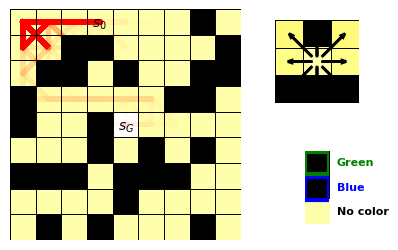

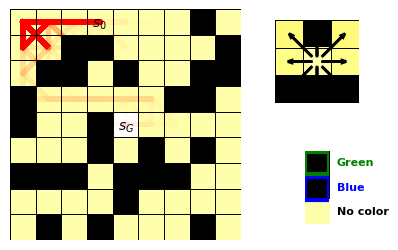

In [13]:
G.plot_world(f'Only S1', c, c_cfg.state_penalties, c_cfg.action_penalties, c_cfg.color_penalties, temp_demo, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)

In [38]:
temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==0.9) &  ((df['type']=='SOFAI w/ S1') )  ]
df.to_csv("all_data_s1.csv")

In [1]:

df

NameError: name 'df' is not defined

In [14]:
#x='traj_n'
#y='perc_usage'

#g=sns.lineplot(x=x, y=y, data=temp_df, hue_order=['s1','s2'], hue="sub_type",markers=True, dashes=False)

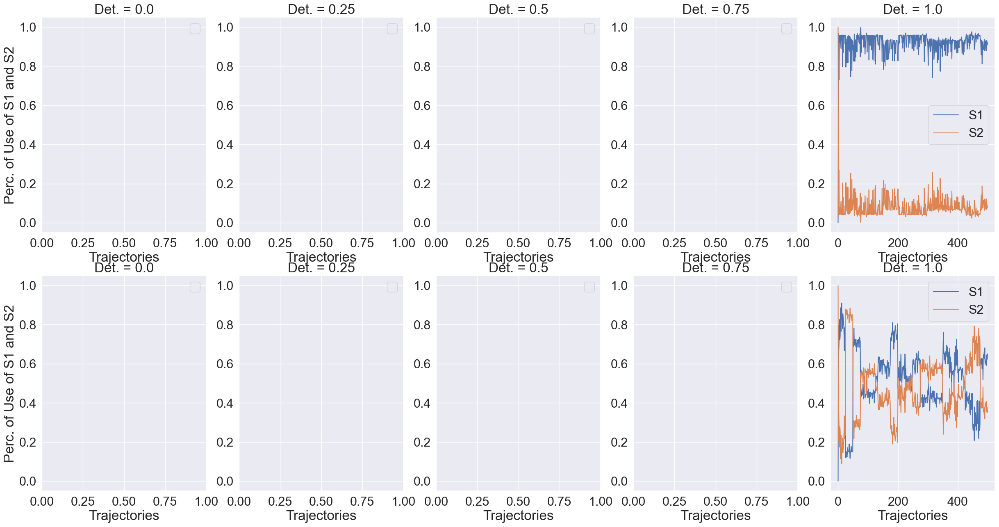

In [15]:
x='traj_n'
y='perc_usage'
#y='avg_reward'
#y='avg_time'
filename = y+'_risk'
title="Avg frac. of times per sub-system, risk avers="

plot_subtype(x,y,df,"sub_type",title,filename, list_threshold3=[0,1])

,Unnamed: 0,traj_n,length,reward,time,sub_type,time_agent,avg_time,reward_agent,avg_reward,...,Length,Reward,Viol,S1_Usage,t1,t2,t3,t4,t6,t7
0,0,0,8,-22.000000,167,S1,0,NaN,0.000000,NaN,...,8.0,-22.000000,0.0,0,200,0.8,0,0,1,0.5
1,0,0,8,-22.000000,167,S2,167,20.875000,-22.000000,-2.750000,...,8.0,-22.000000,0.0,0,200,0.8,0,0,1,0.5
2,0,0,6,-14.000000,121,S1,0,NaN,0.000000,NaN,...,6.0,-14.000000,0.0,0,200,0.8,1,0,1,0.5
3,0,0,6,-14.000000,121,S2,121,20.166667,-14.000000,-2.333333,...,6.0,-14.000000,0.0,0,200,0.8,1,0,1,0.5
4,0,0,9,-76.000000,199,S1,0,NaN,0.000000,NaN,...,9.0,-76.000000,0.5,0,200,0.8,1,0,1,0.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,499,499,4,-101.313708,20,S2,19,19.000000,4.343146,4.343146,...,4.0,-101.313708,1.0,0,200,0.8,1,0,1,0.5
59996,499,499,20,-170.284271,69,S1,8,0.470588,-118.970563,-6.998268,...,20.0,-170.284271,1.0,0,200,0.8,1,0,1,0.5
59997,499,499,20,-170.284271,69,S2,61,20.333333,-51.313708,-17.104569,...,20.0,-170.284271,1.0,0,200,0.8,1,0,1,0.5
59998,499,499,22,-216.000000,22,S1,22,1.000000,-216.000000,-9.818182,...,22.0,-216.000000,1.5,0,200,0.8,1,0,1,0.5


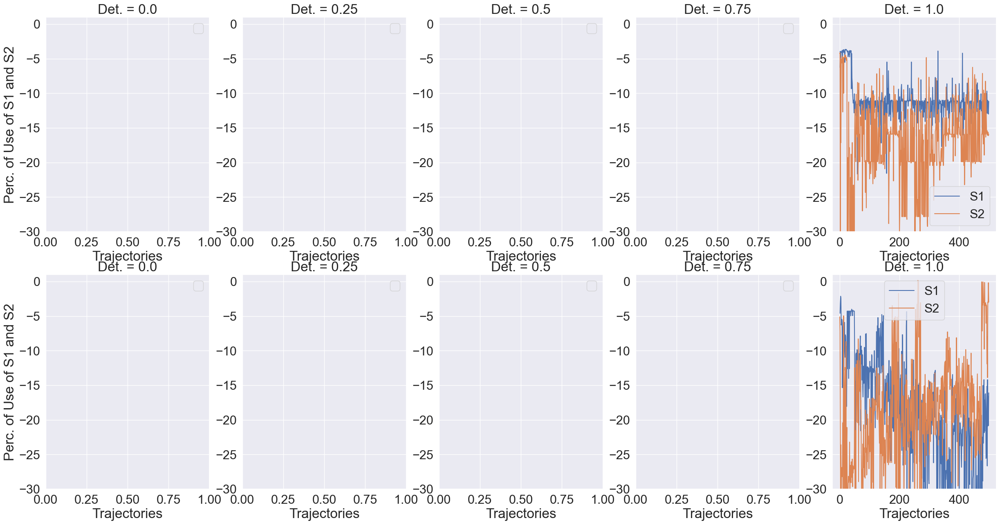

In [16]:
x='traj_n'
y='avg_reward'
#y='avg_time'
filename = y+'_risk_'
title="Avg reward per sub-system, risk avers="

plot_subtype(x,y,df, "sub_type",title,filename, list_threshold3=list_threshold3, dropna = True, min_label=-30, max_label=1)


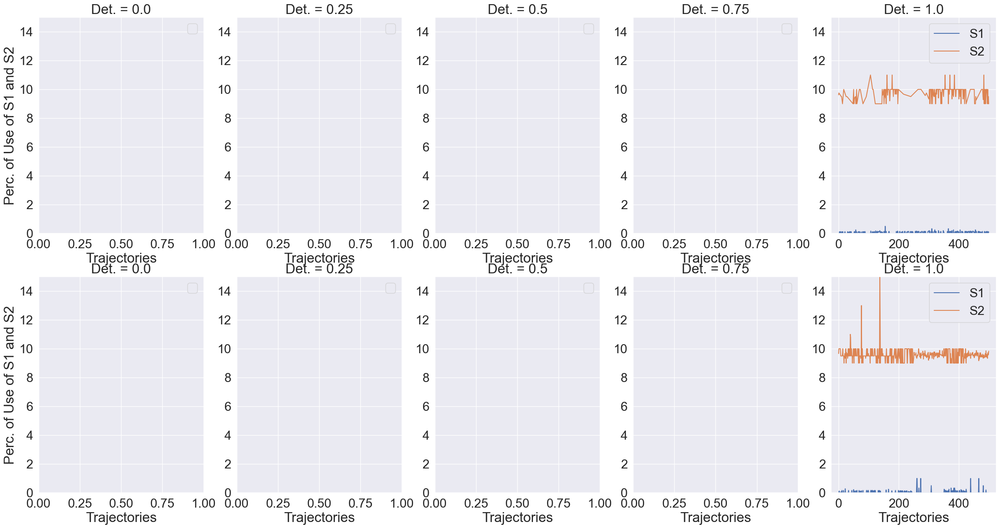

In [25]:
x='traj_n'
y='avg_time'
filename = y+'_time'
title="Avg time per sub-system, risk avers="

plot_subtype(x,y,df, "sub_type",title,filename, list_threshold3=list_threshold3, dropna = True, max_label=15)

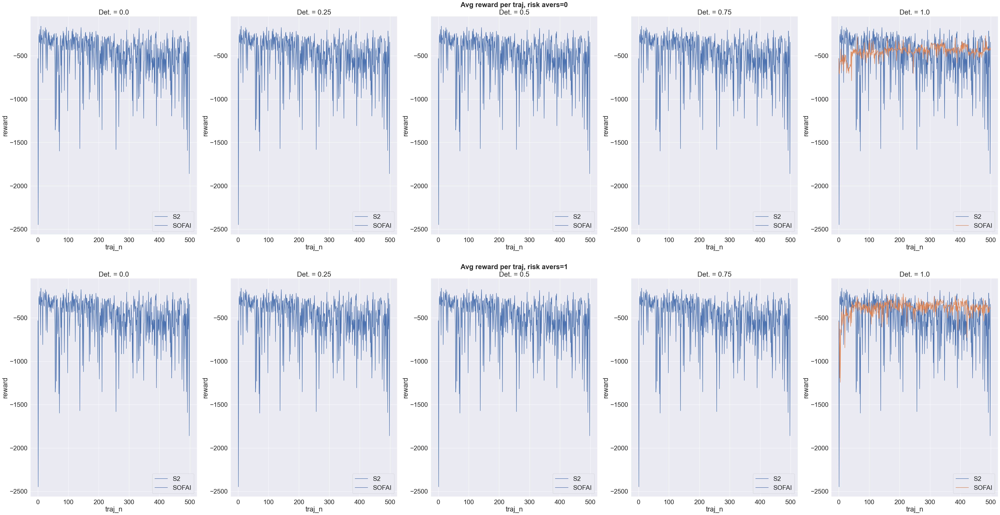

In [19]:
x='traj_n'
#y='perc_usage'
y='reward'
#y='time'


filename = 'avg_reward_per_traj'
title="Avg reward per traj, risk avers="

plot_type(x,y,df,"type",title,filename, list_threshold3=[0,1])


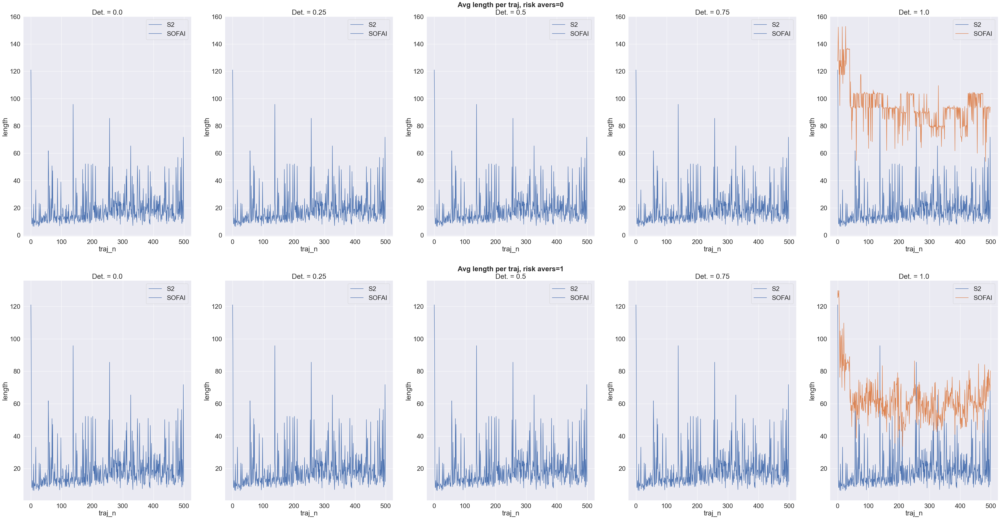

In [20]:
x='traj_n'
y='length'

filename = 'avg_length_per_traj'
title="Avg length per traj, risk avers="

plot_type(x,y,df,"type",title,filename, list_threshold3=list_threshold3)

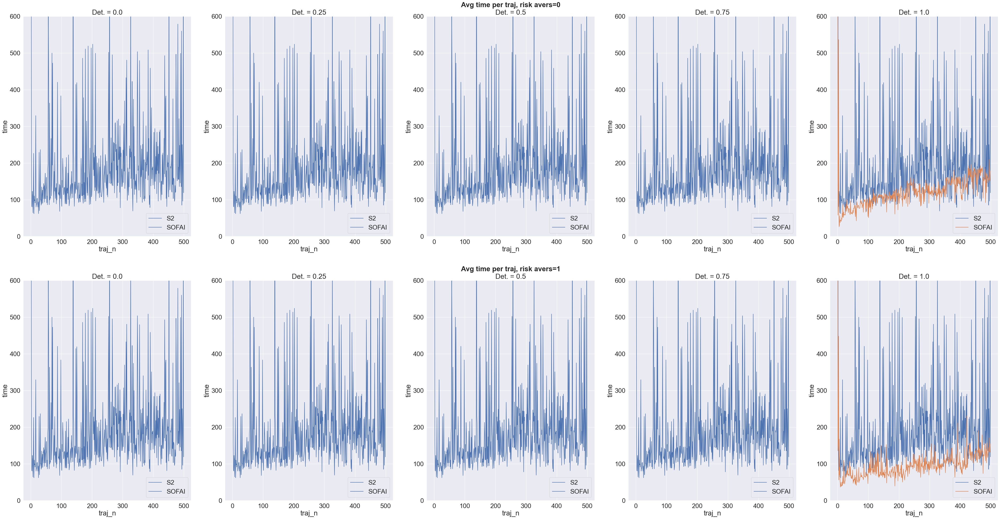

In [22]:
x='traj_n'
y='time'
filename = 'avg_time_withS1_per_traj'
title="Avg time per traj, risk avers="

plot_type(x,y,df,"type",title,filename, list_threshold3=list_threshold3, max_label=600)

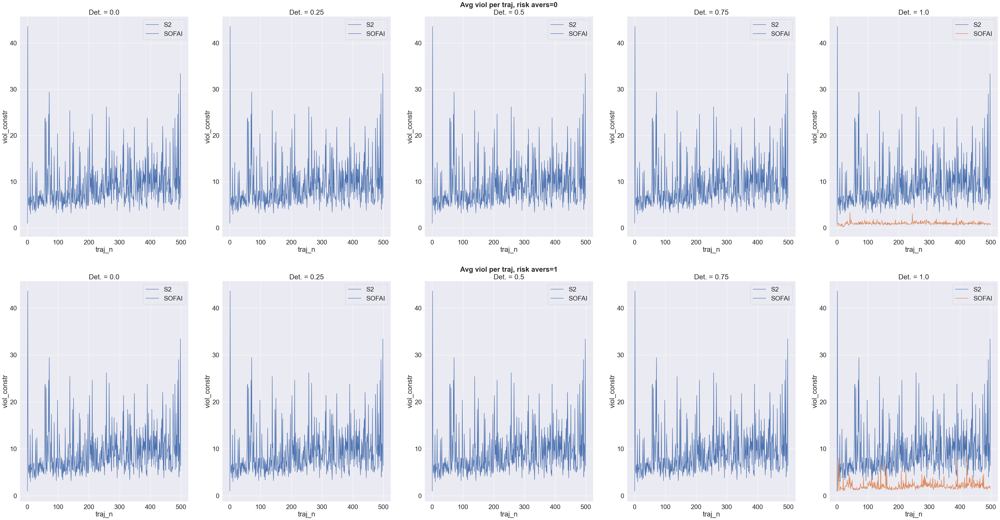

In [23]:
x='traj_n'
y='viol_constr'
filename = 'avg_viol_aggregated_per_traj'
title="Avg viol per traj, risk avers="

plot_type(x,y,df,"type",title,filename, list_threshold3=list_threshold3, dropna=True)

In [25]:
df.loc[(df['type']=='SOFAI w/ S1 ra=1.0') & (df['traj_n']==1)  & (df['t3']==1)]
#df['type']
df.to_csv("test_502.csv")

In [30]:
df.loc[(df['type']=='SOFAI w/ S1 ra=1.0') & (df['traj_n']==69)  & (df['t3']==1) ][['perc_usage', 'usage','length']]

,perc_usage,usage,length
69,0.75,6,8
69,0.25,2,8
69,0.40,2,5
69,0.60,3,5


In [ ]:
temp_dictionary = demo_list[-3].__dict__

In [ ]:
mca_agents[4].trajectory_stat[2]

In [ ]:
mca_agents[4].modelSelf.trajectories[:]

In [ ]:
r[4]

In [ ]:
blue, green, cs, ca, start, goal = generate_constraints(9, n_constraints=n_constraints,goal = goal, action=n_actions)


In [ ]:
n, n_cfg, demo_n, f1 = create_world('Nominal', blue, green, start=start, goal=goal, n_trajectories=200, p_slip=p_slip, draw=True)

In [ ]:
print(mca_agents[4].modelSelf.getReward(26,1))
print(mca_agents[4].modelSelf.getRewardS2(26, maxLike=False, verbose=True))

In [ ]:
mca_agents[4].modelSelf.trajectories[0].transitions()[-1][2]

In [ ]:
mca_agents[4].modelSelf.ntra_per_transition[8,2,1]

In [ ]:
action = 1
print(sum(list(mca_agents[4].modelSelf.prob_s2[8, 2,action].values())))
print((list(mca_agents[4].modelSelf.prob_s2[8, 2,action].keys())))

for action in range(6):
    print(sum(np.array(list(mca_agents[4].modelSelf.prob_s2[8, 2,action].keys()))*np.array(list(mca_agents[4].modelSelf.prob_s2[8, 2,action].values())))/sum(list(mca_agents[4].modelSelf.prob_s2[8, 2,action].values())))
print(mca_agents[4].modelSelf.ntra_per_stateAction_s2[(8, 2)])
print(mca_agents[4].modelSelf.ntra_per_stateAction[(8, 2)])

In [ ]:
#np.where(np.array(list(mca_agents[4].modelSelf.prob_s2[8,1,1,].values()))==11)
sum(list(mca_agents[4].modelSelf.prob_s2[8,2,1].keys()))/sum(list(mca_agents[4].modelSelf.prob_s2[8,2,1].values()))

In [ ]:
r = mca_agents[4].reflect(0.1)
print(sum(r[3]))
print(f"Temp: {mca_agents[4].temperature}")

In [ ]:
values_new = []
values = []
values_s2 = []
delta = []
epsilon = 1E-9
initial = 135
final = 150
for i in range(initial, initial+len(r[2])):
    '''if r[3][i]:
        values_new.append((sum(r[1][i])))#/(len(r[1][i])*168)))
    else:
        values_new.append((sum(mca.action_reward[i])))#/sum(mca.time_stat[i])))'''
    values.append(-sum(mca_agents[4].action_reward[i])*sum(mca_agents[4].time_stat[i]))
    values_new.append(-sum(r[1][i-initial])*sum(r[2][i-initial]))
    values_s2.append(-sum(mca_s2.action_reward[i])*sum(mca_s2.time_stat[i]))
    #print(f"{values[-1],values_new[-1]}")
    delta.append(math.log(values[-1]+epsilon,2) - math.log(values_new[-1]+epsilon,2))

In [ ]:
print(f"Temp: {mca_agents[4].temperature}")
threshold_delta = -0.0
compare_traj = np.array(mca_agents[4].modelSelf.trajectories[initial:final])[np.where(np.array(delta)< threshold_delta)[0]]
compare_traj = np.concatenate((np.array(r[0])[np.where(np.array(delta)>= threshold_delta)[0]], compare_traj), axis=0)
#print(Trajectory(compare_traj[0]))

epsilon = 1E-4
origTraj = np.zeros((size * size, 8, size * size)) + epsilon
for trajectory in mca_agents[4].modelSelf.trajectories[initial: final]:
    #total += len(trajectory.transitions())
    for transition in trajectory.transitions():
        #print(f"prima:{origTraj[transition]}")
        origTraj[transition] += 1
        #print(f"dopo:{origTraj[transition]}\n")
        
origTraj = origTraj / sum(np.reshape(origTraj, (-1,)))

newtraj = np.zeros((size * size, 8, size * size)) + epsilon
for trajectory in compare_traj:
    for transition in trajectory.transitions():
        newtraj[tuple(transition)] += 1	
newtraj = newtraj / sum(np.reshape(newtraj, (-1,)))



distance.jensenshannon(np.reshape(newtraj, (-1,)),np.reshape(origTraj, (-1,)))


In [ ]:
print(f"improvements {r[3]}")
values_new = []
values = []
delta = []
epsilon = 1E-9
initial = 135
final = 150
for i in range(initial, initial+len(r[2])):
    '''if r[3][i]:
        values_new.append((sum(r[1][i])))#/(len(r[1][i])*168)))
    else:
        values_new.append((sum(mca.action_reward[i])))#/sum(mca.time_stat[i])))'''
    values.append(-sum(mca_agents[4].action_reward[i])*sum(mca_agents[4].time_stat[i]))
    values_new.append(-sum(r[1][i-initial])*sum(r[2][i-initial]))
    #print(f"{values[-1],values_new[-1]}")
    delta.append(math.log(values[-1]+epsilon,2) - math.log(values_new[-1]+epsilon,2))

compare_traj = np.array(mca_agents[4].modelSelf.trajectories[initial:final])[np.where(np.array(delta)< threshold_delta)[0]]
compare_traj = np.concatenate((np.array(r[0])[np.where(np.array(delta)>= threshold_delta)[0]], compare_traj), axis=0)


size = mca_agents[4].modelSelf.grid.world.size
epsilon = 1E-4
origTraj = np.zeros((size * size, 8, size * size)) + epsilon
for trajectory in mca_agents[4].modelSelf.trajectories[initial: final]:
    #total += len(trajectory.transitions())
    for transition in trajectory.transitions():
        origTraj[transition] += 1	
origTraj = origTraj / sum(np.reshape(origTraj, (-1,)))

newtraj = np.zeros((size * size, 8, size * size)) + epsilon
for trajectory in compare_traj:
    for transition in trajectory.transitions():
        newtraj[tuple(transition)] += 1	
newtraj = newtraj / sum(np.reshape(newtraj, (-1,)))

distance.jensenshannon(np.reshape(newtraj, (-1,)),np.reshape(origTraj, (-1,)))


In [ ]:
#New is over old, i.e. it is worst, because of the higher time taken to compute the new trajectory
plt.figure(figsize=(20,10))
plt.plot(values_s2, label="S2")
plt.plot(values, label="Old")
plt.legend()

In [ ]:
for index, transition in enumerate(l.transitions()):
    print(index)

In [ ]:
np.array(mca_agents[4].modelSelf.trajectories[initial:final])[np.where(np.array(delta)< threshold_delta)[0]]

In [ ]:
compare_traj

In [ ]:
np.array(mca_agents[4].modelSelf.trajectories[0:50])[np.where(np.array(delta)< threshold_delta)[0]]

In [ ]:
np.array(r[0])[np.where(np.array(delta)>= threshold_delta)[0]]

In [ ]:
i = 4
mca_agents[4].modelSelf.trajectories[i]

In [ ]:
mca_agents[3].modelSelf.trajectories[i]

In [ ]:
mca_agents[4].trajectory_stat[i]

In [ ]:
mca_agents[3].trajectory_stat[i]

In [ ]:
sum(map(sum,mca_agents[3].action_reward))

In [ ]:
sum(map(sum,mca_agents[4].action_reward))

In [ ]:
mca_agents[4].s1.count_random

In [ ]:
sum(np.reshape(newtraj, (-1,)))

In [82]:
df.type

0                         S2
1                         S2
2         SOFAI w/ S1 ra=0.0
3         SOFAI w/ S1 ra=0.0
4        SOFAI w/ S1 ra=0.25
                ...         
59995     SOFAI w/ S1 ra=0.5
59996    SOFAI w/ S1 ra=0.75
59997    SOFAI w/ S1 ra=0.75
59998     SOFAI w/ S1 ra=1.0
59999     SOFAI w/ S1 ra=1.0
Name: type, Length: 60000, dtype: object

In [ ]:
mca_s2.modelSelf.getM()

In [ ]:
mca_agents[4].modelSelf.getAvgPartialReward(63)

In [78]:
!pwd
#df = pd.read_csv("all_data_1.csv")
df = pd.read_csv("all_data_1.csv")
for index, value in df[:300].iterrows():
    print(str(value['traj_n'])+" "+str(value['perc_usage']))

/Users/aloreggia/Documents/GitHub/wmca/notebooks
0 0.0
0 1.0
0 0.0
0 1.0
0 0.0
0 1.0
0 0.0
0 1.0
0 0.0
0 1.0
0 0.0
0 1.0
1 0.0
1 1.0
1 0.0
1 1.0
1 0.3
1 0.7
1 0.2222222222222222
1 0.7777777777777778
1 0.5714285714285714
1 0.4285714285714285
1 0.6666666666666666
1 0.3333333333333333
2 0.0
2 1.0
2 0.0
2 1.0
2 0.0
2 1.0
2 0.0
2 1.0
2 0.0
2 1.0
2 0.0
2 1.0
3 0.0
3 1.0
3 0.0
3 1.0
3 0.1428571428571428
3 0.8571428571428571
3 0.5057471264367817
3 0.4942528735632184
3 0.6888888888888889
3 0.3111111111111111
3 1.0
3 0.0
4 0.0
4 1.0
4 0.0
4 1.0
4 0.4
4 0.6
4 0.3333333333333333
4 0.6666666666666666
4 0.75
4 0.25
4 0.8
4 0.2
5 0.0
5 1.0
5 0.0
5 1.0
5 0.2857142857142857
5 0.7142857142857143
5 0.2857142857142857
5 0.7142857142857143
5 0.5
5 0.5
5 0.8888888888888888
5 0.1111111111111111
6 0.0
6 1.0
6 0.1
6 0.9
6 0.4545454545454545
6 0.5454545454545454
6 0.2941176470588235
6 0.7058823529411765
6 0.4
6 0.6
6 0.1379310344827586
6 0.8620689655172413
7 0.0
7 1.0
7 0.5
7 0.5
7 0.6666666666666666
7 0.333333

In [79]:
df['sub_type'] = df['sub_type'].replace(['s1'], 'S1')
df['sub_type'] = df['sub_type'].replace(['s2'], 'S2')
#df['type'] = df['type'].replace(['SOFAI w/ S1 ra=1.0'], 'SOFAI')

In [39]:
#plot_type_new(x=x, y='Viol', df0=temp_df_0, df1=temp_df_1, hue='type', title='', filename='viol_constr')
fig=plt.figure(figsize=(12, 7))
sns.set(rc={'figure.figsize':(11.7,8.27)})
sns.set_theme(style="whitegrid")
sns.set(font_scale=2)
#sns.color_palette("viridis", as_cmap=True)

temp_df0 = ra0.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=1.0')) ]
temp_df1 = ra1.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=1.0')) ]
#temp_df['type'] = df['type'].replace(['SOFAI w/ S1 ra=1.0'], 'SOFAI')

#if dropna : temp_df = temp_df.dropna()


plt.xlabel("Trajectories")
plt.ylabel("n. Violated Constraints")
#g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df0, markers=True, dashes=False, ci=None )
#g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df1, markers=True, dashes=False, ci=None )
label = 'viol_constr'

colors = ['#747FE3', '#32cd32', '#E37346']
sns.set_palette(sns.color_palette(colors))

g=sns.scatterplot(x='traj_n', y=label, data=temp_df0, color="red")
g=sns.scatterplot(x='traj_n', y=label, data=temp_df1, color="yellow")
plt.legend(labels=['Det = 0', 'Det = 1'])
#if max_label: g.set_ylim([min_label, max_label])
plt.legend(labels=['Det = 0', 'Det = 1'])
g.set_ylim([0, 50])

#plt.legend(loc='upper right')
#plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)


plt.savefig(f'{label}.png')
  
'''
fig=plt.figure(figsize=(12, 7))
sns.set(rc={'figure.figsize':(11.7,8.27)})
sns.set_theme(style="whitegrid")
sns.set(font_scale=2)
sns.color_palette("viridis", as_cmap=True)

label = 'viol_constr'
label = 'time'
#label = 'reward'
#label = 'length'

temp_df = df.loc[(df['type']=='S2')  | (df['type']=='SOFAI w/ S1 ra=1.0')] #| (df['type']=='s1_nb') 
temp_df['type'] = df['type'].replace(['SOFAI w/ S1 ra=1.0'], 'SOFAI')
df_means = temp_df.groupby(by=['type','traj_n']).agg(label=(label,'mean'))
plt.legend(labels=['S2', 'SOFAI'])

 
colors = ['#747FE3', '#32cd32', '#E37346']
sns.set_palette(sns.color_palette(colors))

plt.xlabel("Trajectories")
plt.ylabel("Time")
g = sns.scatterplot(x='traj_n', y='label', data=df_means, hue='type')
#g.set_ylim([0, 1000])
g.legend_.set_title(None)
plt.savefig(f'{label}.png')
'''

0                         S2
1                         S2
2         SOFAI w/ S1 ra=0.0
3         SOFAI w/ S1 ra=0.0
4        SOFAI w/ S1 ra=0.25
                ...         
59995     SOFAI w/ S1 ra=0.5
59996    SOFAI w/ S1 ra=0.75
59997    SOFAI w/ S1 ra=0.75
59998                  SOFAI
59999                  SOFAI
Name: type, Length: 60000, dtype: object

In [ ]:
fig=plt.figure(figsize=(12, 7))
sns.set(rc={'figure.figsize':(11.7,8.27)})
sns.set_theme(style="whitegrid")
sns.set(font_scale=2)
sns.color_palette("viridis", as_cmap=True)
fig.set_title(f'Det. = 1.0')
temp_df = df.loc[(df['traj_n']>=0) & (((df['t3']==t3) & (df['type']=='SOFAI w/ S1 ra=1.0')) | (df['t3']==0))].dropna() #| (df['type']=='s1_nb') 
if dropna : temp_df = temp_df.dropna()
#g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['S2', 'SOFAI w/ S1 ra=1.0'], hue=hue,markers=True, ci=None, dashes=False)
plt.legend(labels=['S2', 'SOFAI'])
df_means = temp_df.groupby(['type','traj_n'])['time'].mean().plot()
#g = sns.scatterplot(ax=ax, x=x, y=y, data=temp_df, hue_order=['s1','s2'], hue=hue)
g = sns.scatterplot(ax=ax, y=y, data=df_means, size=10, hue=hue)
if max_label: g.set_ylim([min_label, max_label])
#axis[0,1].set_title('No Myopic')

In [1]:
fig=plt.figure(figsize=(12, 7))
sns.set(rc={'figure.figsize':(11.7,8.27)})
sns.set_theme(style="whitegrid")
sns.set(font_scale=2)
sns.color_palette("viridis", as_cmap=True)

label = 'viol_constr'
label = 'time'
#label = 'reward'
#label = 'length'

temp_df = df.loc[(df['type']=='S2')  | (df['type']=='SOFAI w/ S1 ra=0.75')] #| (df['type']=='s1_nb') 
temp_df['type'] = df['type'].replace(['SOFAI w/ S1 ra=0.75'], 'SOFAI')
df_means = temp_df.groupby(by=['type','traj_n']).agg(label=(label,'mean'))
plt.legend(labels=['S2', 'SOFAI'])

 
colors = ['#747FE3', '#32cd32', '#E37346']
sns.set_palette(sns.color_palette(colors))

plt.xlabel("Trajectories")
plt.ylabel("Time")
g = sns.scatterplot(x='traj_n', y='label', data=df_means, hue='type')
g.set_ylim([0, 1000])
g.legend_.set_title(None)
plt.savefig(f'{label}.png')

NameError: name 'plt' is not defined

In [116]:
temp_df.groupby(by=['type','traj_n']).agg(label=(label,'mean'))

label
type               traj_n        
S2                 0        896.4
                   1        593.1
                   2       1534.8
                   3        376.3
                   4        763.4
...                           ...
SOFAI w/ S1 ra=1.0 495       69.0
                   496       73.2
                   497       49.2
                   498       76.3
                   499       49.1

[1000 rows x 1 columns]

In [117]:
temp_df[label]

0      167
0      139
1      125
1       40
1       40
      ... 
497      0
498    377
498     64
499    210
499     22
Name: time, Length: 10977, dtype: int64

/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_50925/2623451561.py:13: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  g=sns.lineplot(x=x, y=y, data=temp_df, hue_order=['S1','S2'], ci=None, hue='sub_type', markers=True, dashes=False)


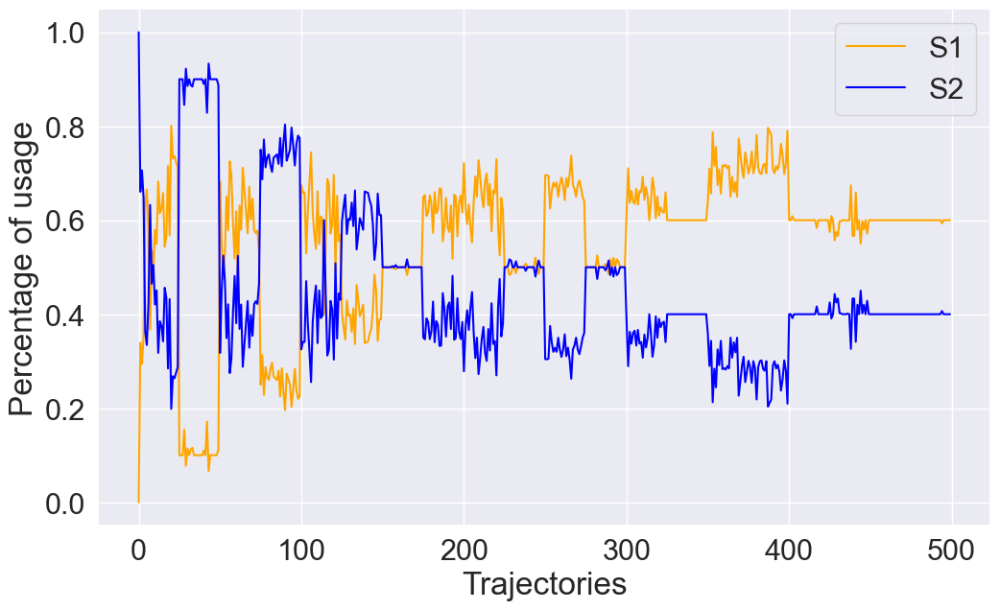

In [83]:
fig=plt.figure(figsize=(12, 7))
x='traj_n'
y='perc_usage'
temp_df = df.loc[(df['type']=='SOFAI w/ S1 ra=1.0')]

colors = ['orange', 'blue', '#E37346']
sns.set_palette(sns.color_palette(colors))

plt.legend(labels=['S1', 'S2'])
plt.xlabel("Trajectories")
plt.ylabel("Percentage of usage")

g=sns.lineplot(x=x, y=y, data=temp_df, hue_order=['S1','S2'], ci=None, hue='sub_type', markers=True, dashes=False)
g.legend_.set_title(None)
plt.savefig(f'{y}.png', bbox_inches='tight')

In [134]:
plot_subtype(x,y,df,"sub_type",title,filename, list_threshold3=list_threshold3)

0                      S2
0                      S2
0      SOFAI w/ S1 ra=1.0
0      SOFAI w/ S1 ra=1.0
1                      S2
              ...        
498    SOFAI w/ S1 ra=1.0
499                    S2
499                    S2
499    SOFAI w/ S1 ra=1.0
499    SOFAI w/ S1 ra=1.0
Name: type, Length: 20000, dtype: object

In [40]:
#S1 fully det
mca_agents[4].modelSelf.trajectories[4]

Trajectory([(1, 4, 9), (9, 2, 18), (18, 1, 19), (19, 4, 27), (27, 2, 36), (36, 0, 36), (36, 2, 45), (45, 0, 45), (45, 0, 45), (45, 0, 45), (45, 0, 45), (45, 0, 45), (45, 0, 46), (46, 2, 55), (55, 4, 54), (54, 2, 63), (63, 2, 72), (72, 1, 73), (73, 2, 73), (73, 2, 65), (65, 2, 74), (74, 0, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 65), (65, 2, 74), (74, 0, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 74), (74, 0, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73, 2, 73), (73

In [34]:
#S1 det 0.75
mca_agents[3].modelSelf.trajectories[0]

Trajectory([(8, 2, 17), (17, 2, 26), (26, 2, 35), (35, 0, 34), (34, 0, 33), (33, 2, 42), (42, 0, 41), (41, 0, 40)])

In [35]:
#S1 det 0.5
mca_agents[2].modelSelf.trajectories[0]

Trajectory([(8, 2, 17), (17, 2, 26), (26, 0, 25), (25, 2, 16), (16, 2, 25), (25, 2, 34), (34, 0, 33), (33, 2, 42), (42, 0, 43), (43, 0, 42), (42, 0, 41), (41, 0, 40)])

In [56]:
ra0=pd.read_csv("all_data_0.csv")
ra1=pd.read_csv("all_data_1.csv")

In [33]:
ra0

,Unnamed: 0,traj_n,length,reward,time,sub_type,time_agent,avg_time,reward_agent,avg_reward,...,Length,Reward,Viol,S1_Usage,t1,t2,t3,t4,t6,t7
0,0,0,8,-22.000000,167,s1,0,NaN,0.000000,NaN,...,8.0,-22.000000,0.0,0,200,0.8,0,0,1,0.5
1,0,0,8,-22.000000,167,s2,167,20.875000,-22.000000,-2.750000,...,8.0,-22.000000,0.0,0,200,0.8,0,0,1,0.5
2,0,0,6,-14.000000,118,s1,0,NaN,0.000000,NaN,...,6.0,-14.000000,0.0,0,200,0.8,0,0,1,0.5
3,0,0,6,-14.000000,118,s2,118,19.666667,-14.000000,-2.333333,...,6.0,-14.000000,0.0,0,200,0.8,0,0,1,0.5
4,0,0,9,-76.000000,177,s1,0,NaN,0.000000,NaN,...,9.0,-76.000000,0.5,0,200,0.8,0,0,1,0.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,499,499,7,-210.970563,39,s2,38,19.000000,-9.656854,-4.828427,...,7.0,-210.970563,2.0,0,200,0.8,0,0,1,0.5
59996,499,499,7,-260.970563,21,s1,1,0.166667,-255.313708,-42.552285,...,7.0,-260.970563,2.5,0,200,0.8,0,0,1,0.5
59997,499,499,7,-260.970563,21,s2,20,20.000000,-5.656854,-5.656854,...,7.0,-260.970563,2.5,0,200,0.8,0,0,1,0.5
59998,499,499,201,-1210.627417,322,s1,322,1.601990,-1210.627417,-6.023022,...,201.0,-1210.627417,4.0,0,200,0.8,0,0,1,0.5


In [26]:
def plot_type_new(x, y, df0, df1, hue, title, filename, min_label=0, max_label=None, list_threshold3= None, dropna=False):
         
    sns.set(font_scale=2)
    ci=None
    #print(f"{[min_label, max_label]}")
    sns.set(rc={'figure.figsize':(11.7,8.27)})
    sns.set_theme(style="whitegrid")
    sns.color_palette("viridis", as_cmap=True)
    sns.set(font_scale=2)
    fig = plt.figure(figsize=(30, 15))
    # grid for pairs of subplots
    rows = 1 #len(list_threshold3)
    cols = 5
    grid = plt.GridSpec(rows, cols)
    #print(df['type'])

    #figure, axis = plt.subplots(len(list_threshold3), 2, figsize=(25, 30))
    #plt.tight_layout()
    #print(axis)

    #for index, t3, sub_plot in enumerate(list_threshold3,axis):
    for i in range(rows):
        
        t3 = 0 #list_threshold3[i]
        # create fake subplot just to title set of subplots
        fake = fig.add_subplot(grid[i, :])
        # '\n' is important
        fake.set_title(f'{title+str(t3)}\n', fontweight='semibold')
        fake.set_axis_off()
        
        # create subgrid for two subplots without space between them
        # <https://matplotlib.org/2.0.2/users/gridspec.html>
        gs = gridspec.GridSpecFromSubplotSpec(1, cols, subplot_spec=grid[i, :])

        # real subplot #1
        ax = fig.add_subplot(gs[0])
        ax.set_title(f'Det. = 0.0')
        temp_df0 = df0.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=0.0')) ]
        print(temp_df0[x])
        temp_df1 = df1.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=0.0')) ]
        if dropna : temp_df = temp_df.dropna()
        plt.xlabel("Trajectories")
        plt.ylabel("Average Number of Violated Constraints")
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df0, drawstyle='steps-mid', markers=True, dashes=False, ci=None )
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df1, drawstyle='steps-mid', markers=True, dashes=False, ci=None )
        g=sns.scatterplot(ax=ax, x=x, y=y, data=temp_df0)
        g=sns.scatterplot(ax=ax, x=x, y=y, data=temp_df1)
        plt.legend(labels=['RA0', 'RA1'])
        if max_label: g.set_ylim([min_label, max_label])
        #axis[0,0].set_title('Myopic')'''

        # real subplot #2
        ax = fig.add_subplot(gs[1], sharey=ax)
        ax.set_title(f'Det. = 0.25')
        temp_df0 = df0.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=0.25')) ]
        temp_df1 = df1.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=0.25')) ]
        if dropna : temp_df = temp_df.dropna()
        plt.xlabel("Trajectories")
        plt.ylabel(" ")
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df0, markers=True, dashes=False, ci=None )
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df1, markers=True, dashes=False, ci=None )
        g=sns.scatterplot(ax=ax, x=x, y=y, data=temp_df0)
        g=sns.scatterplot(ax=ax, x=x, y=y, data=temp_df1)
        plt.legend(labels=['RA0', 'RA1'])
        if max_label: g.set_ylim([min_label, max_label])
            
        ax = fig.add_subplot(gs[2], sharey=ax)
        ax.set_title(f'Det. = 0.5')
        temp_df0 = df0.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=0.5')) ]
        temp_df1 = df1.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=0.5')) ]
        if dropna : temp_df = temp_df.dropna()
        plt.xlabel("Trajectories")
        plt.ylabel(" ")
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df0, markers=True, dashes=False, ci=None )
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df1, markers=True, dashes=False, ci=None )
        g=sns.scatterplot(ax=ax, x=x, y=y, data=temp_df0)
        g=sns.scatterplot(ax=ax, x=x, y=y, data=temp_df1)
        plt.legend(labels=['RA0', 'RA1'])
        if max_label: g.set_ylim([min_label, max_label])
            
        ax = fig.add_subplot(gs[3], sharey=ax)
        ax.set_title(f'Det. = 0.75')
        temp_df0 = df0.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=0.75')) ]
        temp_df1 = df1.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=0.75')) ]
        if dropna : temp_df = temp_df.dropna()
        plt.xlabel("Trajectories")
        plt.ylabel(" ")
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df0, markers=True, dashes=False, ci=None )
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df1, markers=True, dashes=False, ci=None )
        g=sns.scatterplot(ax=ax, x=x, y=y, data=temp_df0)
        g=sns.scatterplot(ax=ax, x=x, y=y, data=temp_df1)
        plt.legend(labels=['RA0', 'RA1'])
        if max_label: g.set_ylim([min_label, max_label])
            
        ax = fig.add_subplot(gs[4], sharey=ax)
        ax.set_title(f'Det. = 1.0')
        temp_df0 = df0.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI')) ]
        temp_df1 = df1.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI')) ]
        if dropna : temp_df = temp_df.dropna()
        plt.xlabel("Trajectories")
        plt.ylabel(" ")
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df0, markers=True, dashes=False, ci=None )
        #g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df1, markers=True, dashes=False, ci=None )
        g=sns.scatterplot(ax=ax, x=x, y=y, data=temp_df0)
        g=sns.scatterplot(ax=ax, x=x, y=y, data=temp_df1)
        plt.legend(labels=['RA0', 'RA1'])
        if max_label: g.set_ylim([min_label, max_label])
        #axis[0,1].set_title('No Myopic')

    plt.savefig(filename+'.pdf')
    plt.show()

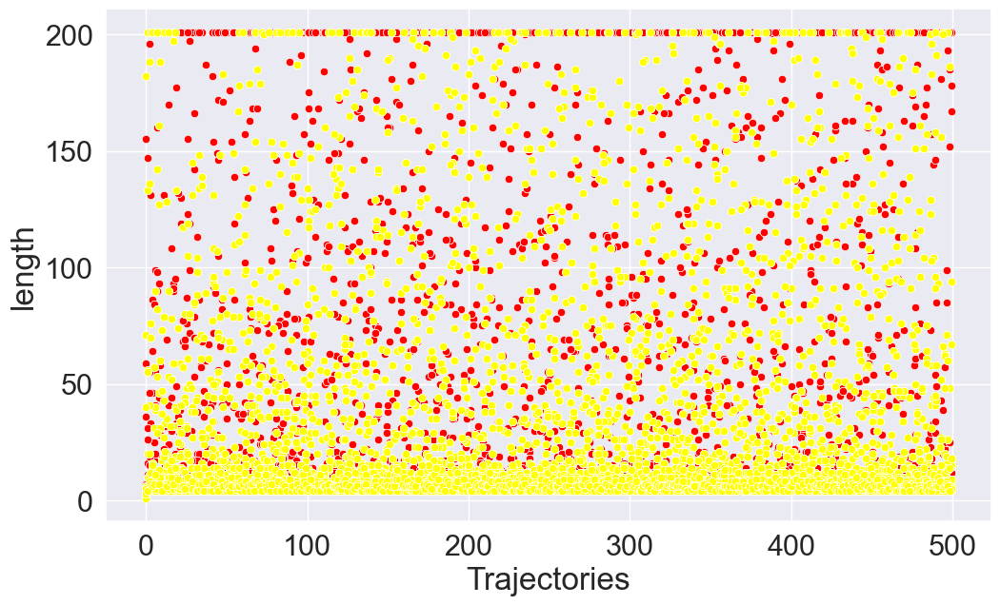

In [53]:
fig=plt.figure(figsize=(12, 7))
x='traj_n'
y='viol_constr'
y='length'
#y='reward'

#temp_df_0 = ra0.loc[(df['type']!='S2')]
#temp_df_1 = ra1.loc[(df['type']!='S2')]
temp_df_0 = df.loc[(df['type']=='SOFAI w/ S1 ra=1.0') & (df['t3']==0)]
temp_df_1 = df.loc[(df['type']=='SOFAI w/ S1 ra=1.0') & (df['t3']==1)]


plt.xlabel("Trajectories")
#plt.ylabel("Percentage of usage")

g=sns.scatterplot(x=x, y=y, data=temp_df_0, color="red")
g=sns.scatterplot(x=x, y=y, data=temp_df_1, color="yellow")
#g=sns.lineplot(x=x, y=y, data=temp_df_1, ci=None, markers=True)
#g.legend_.set_title(None)
#plt.savefig(f'{y}.png', bbox_inches='tight')

In [25]:
plot_type_new(x=x, y='Viol', df0=temp_df_0, df1=temp_df_1, hue='type', title='', filename='viol_constr')

NameError: name 'plot_type_new' is not defined

Series([], Name: traj_n, dtype: int64)


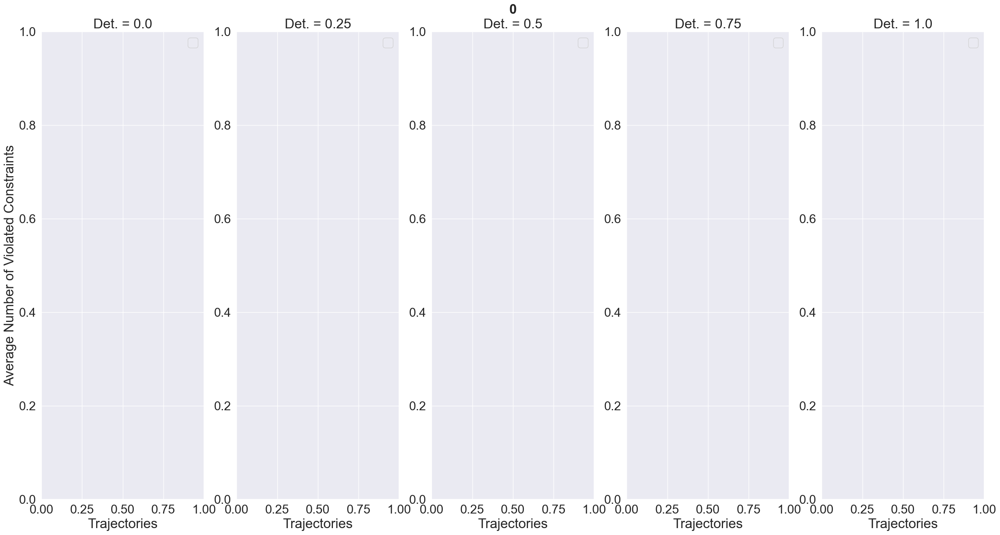

In [27]:


plot_type_new(x=x, y='reward', df0=temp_df_0, df1=temp_df_1, hue='type', title='', filename='reward')

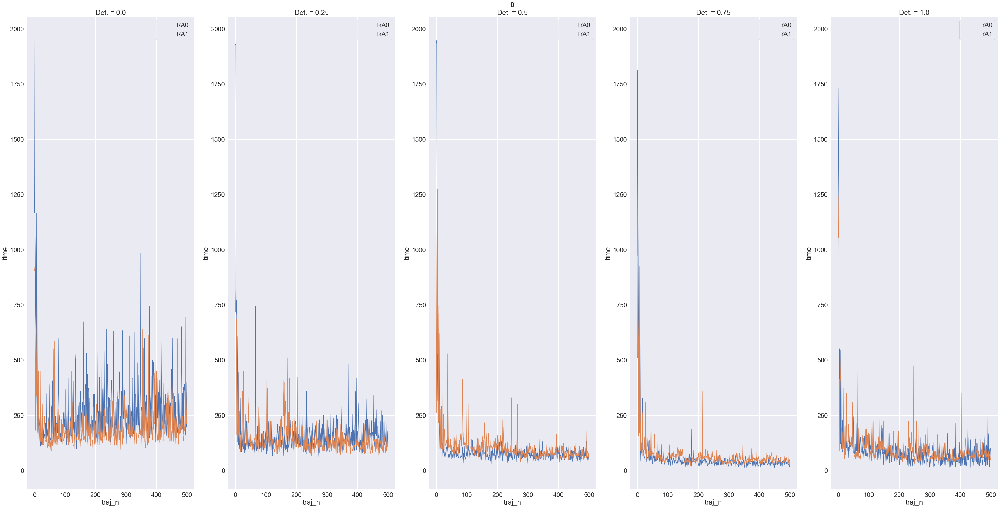

In [87]:
plot_type_new(x=x, y='time', df0=temp_df_0, df1=temp_df_1, hue='type', title='', filename='time')

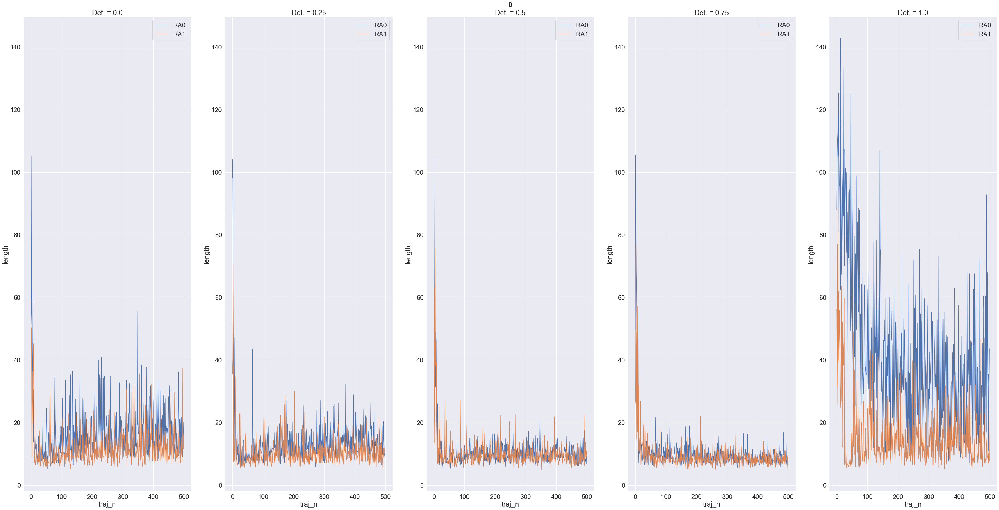

In [89]:
plot_type_new(x=x, y='length', df0=temp_df_0, df1=temp_df_1, hue='type', title='', filename='length')

In [108]:
temp_df1_delete = temp_df_1.loc[(df['traj_n']>=0) & ((df['type']=='SOFAI w/ S1 ra=0.0')) ]

'\nfig=plt.figure(figsize=(12, 7))\nsns.set(rc={\'figure.figsize\':(11.7,8.27)})\nsns.set_theme(style="whitegrid")\nsns.set(font_scale=2)\nsns.color_palette("viridis", as_cmap=True)\n\nlabel = \'viol_constr\'\nlabel = \'time\'\n#label = \'reward\'\n#label = \'length\'\n\ntemp_df = df.loc[(df[\'type\']==\'S2\')  | (df[\'type\']==\'SOFAI w/ S1 ra=1.0\')] #| (df[\'type\']==\'s1_nb\') \ntemp_df[\'type\'] = df[\'type\'].replace([\'SOFAI w/ S1 ra=1.0\'], \'SOFAI\')\ndf_means = temp_df.groupby(by=[\'type\',\'traj_n\']).agg(label=(label,\'mean\'))\nplt.legend(labels=[\'S2\', \'SOFAI\'])\n\n \ncolors = [\'#747FE3\', \'#32cd32\', \'#E37346\']\nsns.set_palette(sns.color_palette(colors))\n\nplt.xlabel("Trajectories")\nplt.ylabel("Time")\ng = sns.scatterplot(x=\'traj_n\', y=\'label\', data=df_means, hue=\'type\')\n#g.set_ylim([0, 1000])\ng.legend_.set_title(None)\nplt.savefig(f\'{label}.png\')\n'

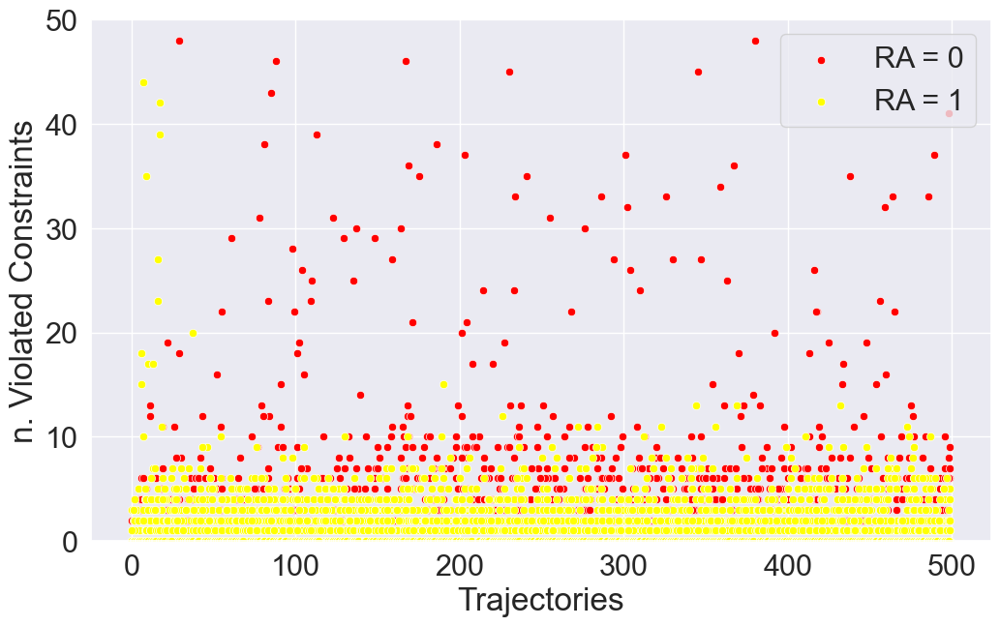

In [50]:
#plot_type_new(x=x, y='Viol', df0=temp_df_0, df1=temp_df_1, hue='type', title='', filename='viol_constr')
fig=plt.figure(figsize=(12, 7))
sns.set(rc={'figure.figsize':(11.7,8.27)})
sns.set_theme(style="whitegrid")
sns.set(font_scale=2)
#sns.color_palette("viridis", as_cmap=True)

temp_df_0 = df.loc[(df['type']=='SOFAI w/ S1 ra=1.0') & (df['t3']==0)]
temp_df_1 = df.loc[(df['type']=='SOFAI w/ S1 ra=1.0') & (df['t3']==1)]
#temp_df['type'] = df['type'].replace(['SOFAI w/ S1 ra=1.0'], 'SOFAI')

#if dropna : temp_df = temp_df.dropna()


plt.xlabel("Trajectories")
plt.ylabel("n. Violated Constraints")
#g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df0, markers=True, dashes=False, ci=None )
#g=sns.lineplot(ax=ax, x=x, y=y, data=temp_df1, markers=True, dashes=False, ci=None )
label = 'viol_constr'

colors = ['#747FE3', '#32cd32', '#E37346']
sns.set_palette(sns.color_palette(colors))

g=sns.scatterplot(x='traj_n', y=label, data=temp_df_0, color="red")
g=sns.scatterplot(x='traj_n', y=label, data=temp_df_1, color="yellow")
plt.legend(labels=['RA = 0', 'RA = 1'])
#if max_label: g.set_ylim([min_label, max_label])
plt.legend(labels=['RA = 0', 'RA = 1'])
g.set_ylim([0, 50])

#plt.legend(loc='upper right')
#plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)


plt.savefig(f'{label}.png')
  
'''
fig=plt.figure(figsize=(12, 7))
sns.set(rc={'figure.figsize':(11.7,8.27)})
sns.set_theme(style="whitegrid")
sns.set(font_scale=2)
sns.color_palette("viridis", as_cmap=True)

label = 'viol_constr'
label = 'time'
#label = 'reward'
#label = 'length'

temp_df = df.loc[(df['type']=='S2')  | (df['type']=='SOFAI w/ S1 ra=1.0')] #| (df['type']=='s1_nb') 
temp_df['type'] = df['type'].replace(['SOFAI w/ S1 ra=1.0'], 'SOFAI')
df_means = temp_df.groupby(by=['type','traj_n']).agg(label=(label,'mean'))
plt.legend(labels=['S2', 'SOFAI'])

 
colors = ['#747FE3', '#32cd32', '#E37346']
sns.set_palette(sns.color_palette(colors))

plt.xlabel("Trajectories")
plt.ylabel("Time")
g = sns.scatterplot(x='traj_n', y='label', data=df_means, hue='type')
#g.set_ylim([0, 1000])
g.legend_.set_title(None)
plt.savefig(f'{label}.png')
'''

In [45]:
temp_df_0 = df.loc[(df['type']=='SOFAI w/ S1 ra=1.0') & (df['t3']==0)]
temp_df_0

,Unnamed: 0,traj_n,length,reward,time,sub_type,time_agent,avg_time,reward_agent,avg_reward,...,Length,Reward,Viol,S1_Usage,t1,t2,t3,t4,t6,t7
2,0,0,29,-160.970563,300,s1,0,NaN,0.000000,NaN,...,29.0,-160.970563,0.5,0,200,0.8,0,0,1,0.5
3,0,0,29,-160.970563,300,s2,300,10.344828,-160.970563,-5.550709,...,29.0,-160.970563,0.5,0,200,0.8,0,0,1,0.5
8,1,1,10,-83.313708,56,s1,0,0.000000,-77.313708,-12.885618,...,10.0,-83.313708,0.5,0,200,0.8,0,0,1,0.5
9,1,1,10,-83.313708,56,s2,56,14.000000,-6.000000,-1.500000,...,10.0,-83.313708,0.5,0,200,0.8,0,0,1,0.5
14,2,2,8,-23.656854,0,s1,0,0.000000,-23.656854,-2.957107,...,8.0,-23.656854,0.0,0,200,0.8,0,0,1,0.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5985,497,497,5,-16.627417,10,s2,10,10.000000,-5.656854,-5.656854,...,5.0,-16.627417,0.0,0,200,0.8,0,0,1,0.5
5990,498,498,5,-18.284271,10,s1,0,0.000000,-12.627417,-3.156854,...,5.0,-18.284271,0.0,0,200,0.8,0,0,1,0.5
5991,498,498,5,-18.284271,10,s2,10,10.000000,-5.656854,-5.656854,...,5.0,-18.284271,0.0,0,200,0.8,0,0,1,0.5
5996,499,499,7,-27.941125,19,s1,0,0.000000,-16.627417,-3.325483,...,7.0,-27.941125,0.0,0,200,0.8,0,0,1,0.5


In [54]:
df = pd.read_csv("all_data_orig.csv")

In [39]:
str_to_replace = 'SOFAI w/ S1 ra=0.75'
label = 'reward'
#label = "viol_constr"

print(f"{ra0.loc[(ra0['type'] == str_to_replace) & (ra0['t3'] == 0)][label].mean():.4f} ({ra0.loc[(ra0['type'] == str_to_replace) & (ra0['t3'] == 0)][label].std():.4f})")
print(f"{ra1.loc[(ra1['type'] == str_to_replace) & (ra1['t3'] == 1)][label].mean():.4f} ({ra1.loc[(ra0['type'] == str_to_replace) & (ra1['t3'] == 1)][label].std():.4f})")

label = "perc_usage"
print(f"{ra0.loc[(ra0['type'] == str_to_replace) & (ra0['t3'] == 0) & (ra0['sub_type'] == 's2')][label].mean():.4f} ({ra0.loc[(ra0['type'] == str_to_replace) & (ra0['t3'] == 0) & (ra0['sub_type'] == 's2')][label].std():.4f})")
print(f"{ra1.loc[(ra0['type'] == str_to_replace) & (ra1['t3'] == 1) & (ra1['sub_type'] == 's2')][label].mean():.4f} ({ra1.loc[(ra0['type'] == str_to_replace) & (ra1['t3'] == 1) & (ra1['sub_type'] == 's2')][label].std():.4f})")



NameError: name 'ra0' is not defined

In [62]:

label = 'time'
str_to_replace = 'SOFAI w/ S1 ra=0.0'
print(f"{df.loc[(df['type'] == str_to_replace) & (df['t3'] == 1) & (df['sub_type'] == 's1') ][label].mean():.2f} ({df.loc[(df['type'] == str_to_replace) & (df['t3'] == 1)& (df['sub_type'] == 's1')][label].std():.2f})", end= " & ")
str_to_replace = 'SOFAI w/ S1 ra=0.25'
print(f"{df.loc[(df['type'] == str_to_replace) & (df['t3'] == 1)& (df['sub_type'] == 's1')][label].mean():.2f} ({df.loc[(df['type'] == str_to_replace) & (df['t3'] == 1)& (df['sub_type'] == 's1')][label].std():.2f})", end= " & ")
str_to_replace = 'SOFAI w/ S1 ra=0.5'
print(f"{df.loc[(df['type'] == str_to_replace) & (df['t3'] == 1)& (df['sub_type'] == 's1')][label].mean():.2f} ({df.loc[(df['type'] == str_to_replace) & (df['t3'] == 1)& (df['sub_type'] == 's1')][label].std():.2f})", end= " & ")
str_to_replace = 'SOFAI w/ S1 ra=0.75'
print(f"{df.loc[(df['type'] == str_to_replace) & (df['t3'] == 1)& (df['sub_type'] == 's1')][label].mean():.2f} ({df.loc[(df['type'] == str_to_replace) & (df['t3'] == 1)& (df['sub_type'] == 's1')][label].std():.2f})", end= " & ")
str_to_replace = 'SOFAI w/ S1 ra=1.0'
print(f"{df.loc[(df['type'] == str_to_replace) & (df['t3'] == 1)& (df['sub_type'] == 's1')][label].mean():.2f} ({df.loc[(df['type'] == str_to_replace) & (df['t3'] == 1)& (df['sub_type'] == 's1')][label].std():.2f})", end= " \\")


#label = 'reward'
#print(f"{df.loc[(df['type'] == str_to_replace) & (df['t3'] == 1)][label].mean():.2f} ({df.loc[(df['type'] == str_to_replace) & (df['t3'] == 1)][label].std():.2f})")

#label = 'length'
#print(f"{df.loc[(df['type'] == str_to_replace) & (df['t3'] == 1)][label].mean():.2f} ({df.loc[(df['type'] == str_to_replace) & (df['t3'] == 1)][label].std():.2f})")


0.34 (0.56) & 1.50 (1.29) & 1.59 (1.35) & 1.32 (1.22) & 26.28 (110.19) \

In [124]:
list_str_to_replace = ['SOFAI w/ S1 ra=0.0', 'SOFAI w/ S1 ra=0.25','SOFAI w/ S1 ra=0.5','SOFAI w/ S1 ra=0.75','SOFAI w/ S1 ra=1.0']
list_str_to_replace = ['S2',]
label = 'length'
#label = 'reward'
#label = 'time'
#label = 'time_agent'
#label = 'reward_agent'
#label = 'avg_reward'
#label = "viol_constr"

#for str_to_replace in list_str_to_replace:
#    print(f"{df.loc[(df['type'] == str_to_replace) & (df['t3'] == 1)][label].mean():.2f} ({df.loc[(df['type'] == str_to_replace) & (df['t3'] == 1)][label].std():.2f})")

for str_to_replace in list_str_to_replace:
    print(f"{df.loc[(df['type'] == str_to_replace) ][label].mean():.2f} ({df.loc[(df['type'] == str_to_replace) ][label].std():.2f})")

    
#sub_type = 's2'
#for str_to_replace in list_str_to_replace:    
#    print(f"{df.loc[(df['sub_type'] == sub_type) & (df['type'] == str_to_replace) & (df['t3'] == 1)][label].mean():.2f} ({df.loc[(df['sub_type'] == sub_type) & (df['type'] == str_to_replace) & (df['t3'] == 1)][label].std():.2f})")


11.47 (16.25)


In [58]:
df.loc[(df['sub_type'] == 's1') & (df['t3'] == 1)]

,traj_n,length,reward,time,sub_type,time_agent,avg_time,reward_agent,avg_reward,usage,...,Length,Reward,Viol,S1_Usage,t1,t2,t3,t4,t6,t7
0,0,57,-2935.137085,0,s1,0,0.000000,-2935.137085,-51.493633,57,...,57.0,-2935.137085,28.0,0,200,0.8,1,0,1,0.5
0,0,62,-3133.882251,0,s1,0,0.000000,-3133.882251,-50.546488,62,...,62.0,-3133.882251,30.0,0,200,0.8,1,0,1,0.5
0,0,93,-4255.480231,0,s1,0,0.000000,-4255.480231,-45.757852,93,...,93.0,-4255.480231,40.5,0,200,0.8,1,0,1,0.5
0,0,97,-4809.480231,1,s1,1,0.010309,-4809.480231,-49.582270,97,...,97.0,-4809.480231,46.0,0,200,0.8,1,0,1,0.5
1,1,60,-2542.166522,1,s1,1,0.016667,-2542.166522,-42.369442,60,...,60.0,-2542.166522,24.0,0,200,0.8,1,0,1,0.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,495,14,-533.597980,2,s1,2,0.142857,-533.597980,-38.114141,14,...,14.0,-533.597980,5.0,0,200,0.8,1,0,1,0.5
496,496,16,-589.254834,2,s1,2,0.125000,-589.254834,-36.828427,16,...,16.0,-589.254834,5.5,0,200,0.8,1,0,1,0.5
497,497,15,-583.597980,2,s1,2,0.133333,-583.597980,-38.906532,15,...,15.0,-583.597980,5.5,0,200,0.8,1,0,1,0.5
498,498,17,-594.911688,2,s1,2,0.117647,-594.911688,-34.994805,17,...,17.0,-594.911688,5.5,0,200,0.8,1,0,1,0.5


In [18]:
df.type

0                          S2
1                          S2
2          SOFAI w/ S1 ra=0.0
3          SOFAI w/ S1 ra=0.0
4         SOFAI w/ S1 ra=0.25
                 ...         
109995     SOFAI w/ S1 ra=0.5
109996    SOFAI w/ S1 ra=0.75
109997    SOFAI w/ S1 ra=0.75
109998     SOFAI w/ S1 ra=1.0
109999     SOFAI w/ S1 ra=1.0
Name: type, Length: 110000, dtype: object

/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_50925/1164414366.py:11: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  g = sns.barplot(x=x, y=y, hue="type", data=temp_df, palette="autumn", ci=95);


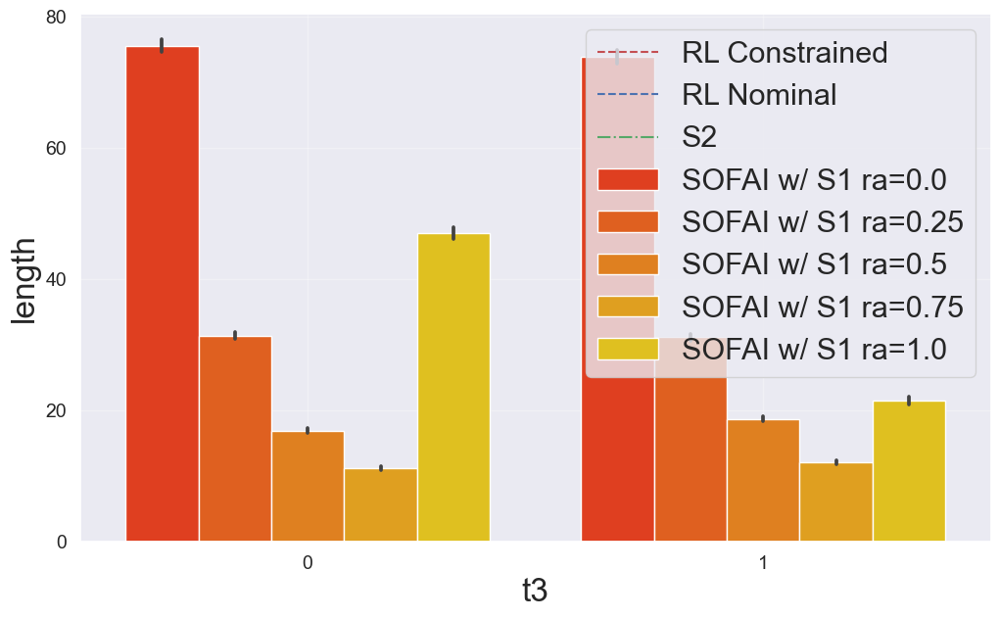

/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_50925/1164414366.py:11: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  g = sns.barplot(x=x, y=y, hue="type", data=temp_df, palette="autumn", ci=95);


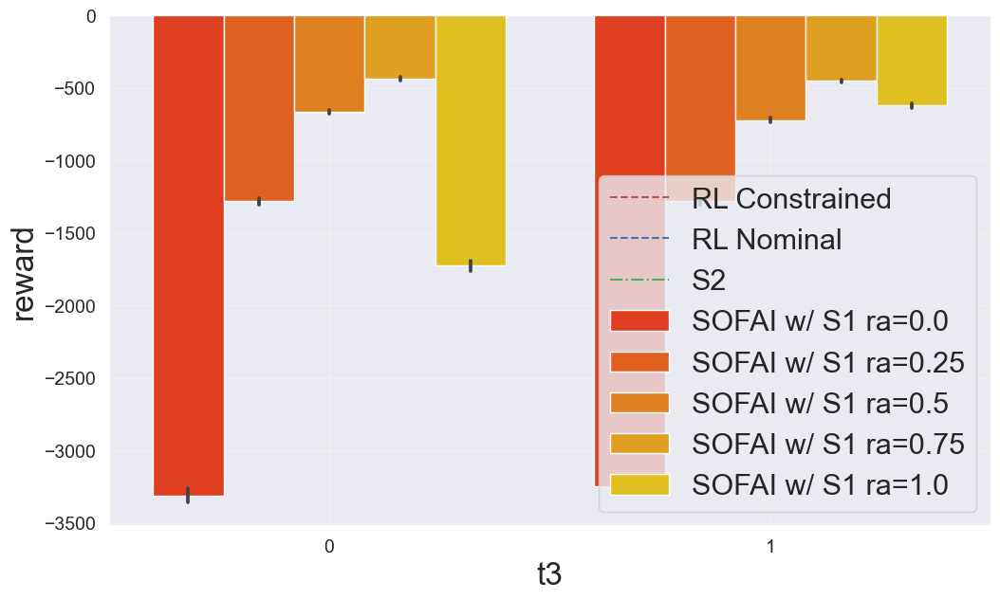

ok


/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_50925/1164414366.py:11: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  g = sns.barplot(x=x, y=y, hue="type", data=temp_df, palette="autumn", ci=95);


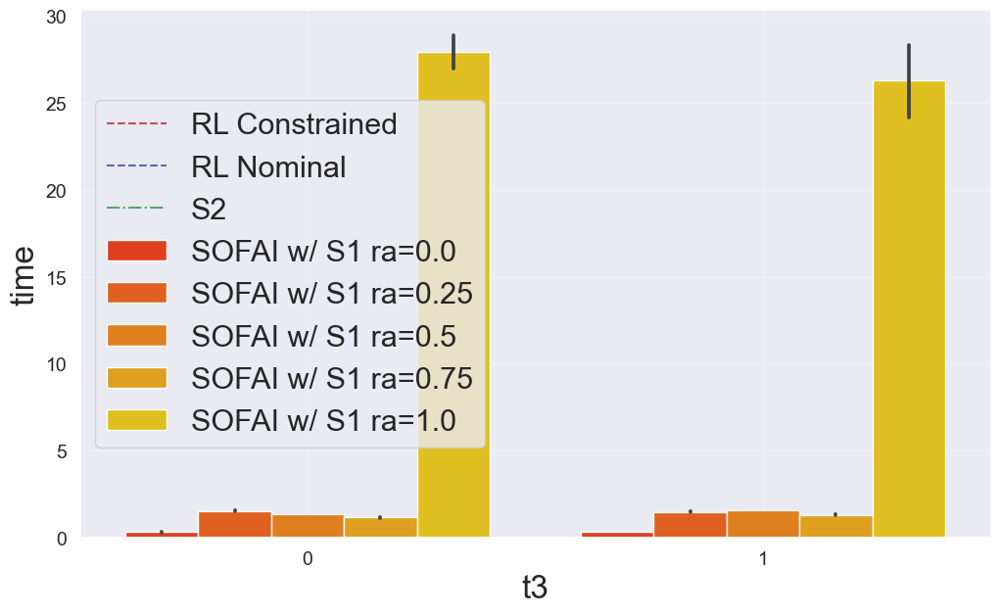

In [28]:
#temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==threshold3) | (df['type']=='S1 noMyopic') | (df['type']=='S2') | (df['type']=='nominal')| (df['type']=='const')]
temp_df = df
#temp_df = temp_df.rename(columns={"01": "SOFAI-01", "s1": "S1-SOFAI"})

label_x = 't3'
label='length'
min_label, max_label = min_max(label, df)
plot_results(temp_df,x=label_x,y=label, min_label=min_label, max_label=20)

label='reward'
min_label, max_label = min_max(label, df)
plot_results(temp_df,x=label_x,y=label, min_label=-100, max_label=max_label)

label='time'
min_label, max_label = min_max(label, df)
print("ok")
plot_results(df,x=label_x,y=label, min_label=min_label, max_label=50)

#label='S1_Usage'
#min_label, max_label = min_max(label, df, df2, df3, df4, df7)
#plot_results(df3,x=label_x,y=label, min_label=min_label, max_label=max_label)

In [29]:
!pwd
#df = pd.read_csv("all_data_1.csv")
df = pd.read_csv("all_data.csv")
for index, value in df[:300].iterrows():
    print(str(value['traj_n'])+" "+str(value['perc_usage']))

/Users/aloreggia/Documents/GitHub/wmca/notebooks
0 0.0
0 1.0
0 0.0
0 1.0
0 0.0
0 1.0
0 0.0
0 1.0
0 0.0
0 1.0
0 0.0
0 1.0
0 0.0
0 1.0
0 0.0
0 1.0
0 0.0
0 1.0
0 0.0
0 1.0
0 0.0
0 1.0
1 0.0
1 1.0
1 0.0099502487562189
1 0.9900497512437813
1 0.0099502487562189
1 0.9900497512437813
1 0.0
1 1.0
1 0.0049751243781094
1 0.9950248756218906
1 0.0099502487562189
1 0.9900497512437813
1 0.0
1 1.0
1 0.0
1 1.0
1 0.0
1 1.0
1 0.0
1 1.0
1 0.0
1 1.0
2 0.0
2 1.0
2 0.0
2 1.0
2 0.0
2 1.0
2 0.0
2 1.0
2 0.0
2 1.0
2 0.0
2 1.0
2 0.0
2 1.0
2 0.0
2 1.0
2 0.0
2 1.0
2 0.0
2 1.0
2 0.0
2 1.0
3 0.0
3 1.0
3 0.0
3 1.0
3 0.0
3 1.0
3 0.5
3 0.5
3 0.8
3 0.2
3 0.6666666666666666
3 0.3333333333333333
3 0.2
3 0.8
3 0.0
3 1.0
3 0.0
3 1.0
3 0.8
3 0.2
3 0.625
3 0.375
4 0.0
4 1.0
4 0.1079136690647482
4 0.8920863309352518
4 0.288135593220339
4 0.711864406779661
4 0.0
4 1.0
4 0.6981132075471698
4 0.3018867924528302
4 0.7093023255813954
4 0.2906976744186046
4 0.0
4 1.0
4 0.0
4 1.0
4 0.3798882681564245
4 0.6201117318435754
4 0.7
4 0.3
4

/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_50925/1164414366.py:11: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  g = sns.barplot(x=x, y=y, hue="type", data=temp_df, palette="autumn", ci=95);


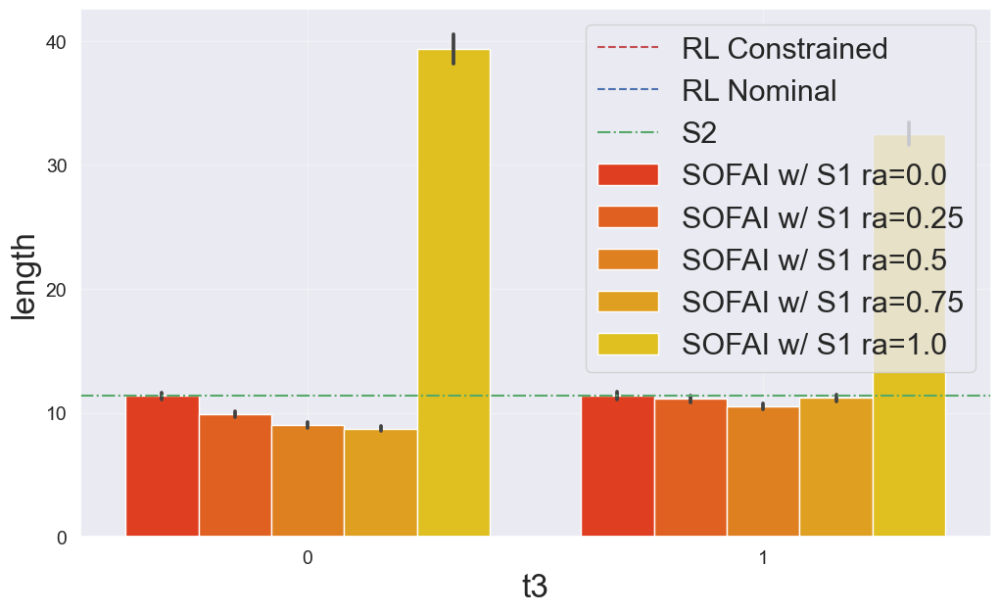

/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_50925/1164414366.py:11: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  g = sns.barplot(x=x, y=y, hue="type", data=temp_df, palette="autumn", ci=95);


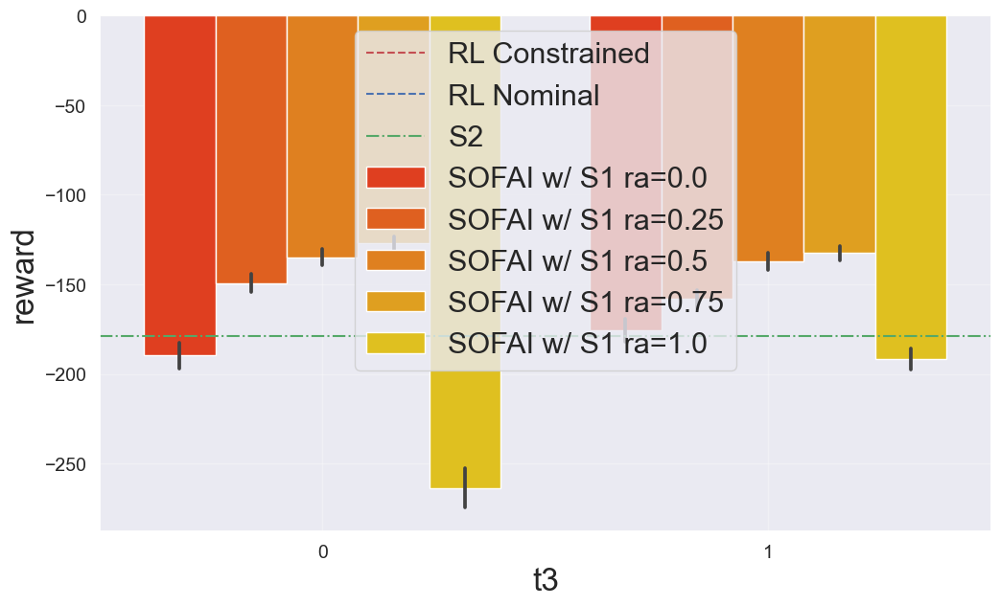

ok


/var/folders/s3/4rklnw7j5hgc9pjv8n2c2_200000gn/T/ipykernel_50925/1164414366.py:11: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  g = sns.barplot(x=x, y=y, hue="type", data=temp_df, palette="autumn", ci=95);


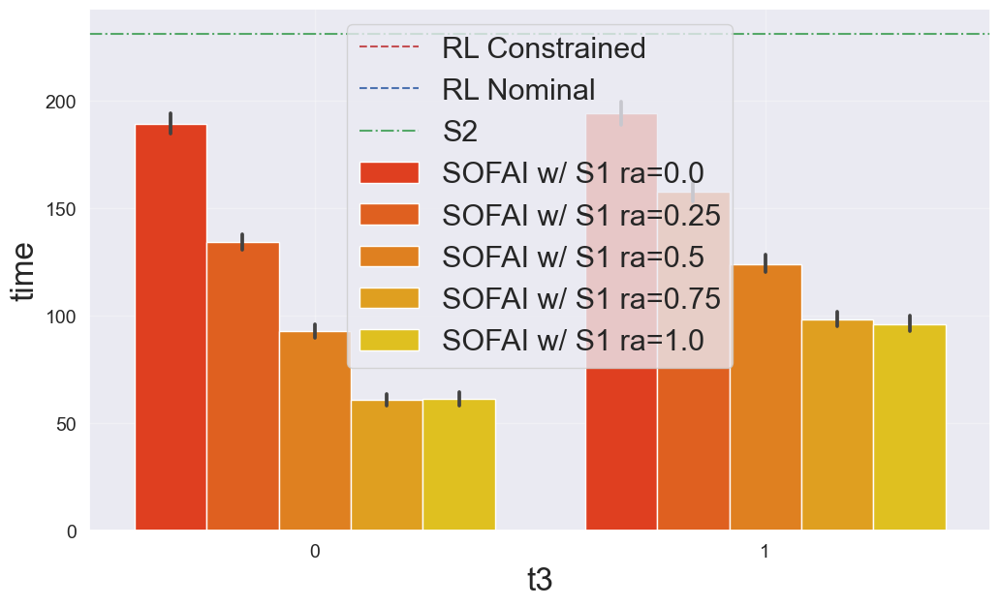

In [31]:
#temp_df = df.loc[(df['traj_n']>=0) & (df['t3']==threshold3) | (df['type']=='S1 noMyopic') | (df['type']=='S2') | (df['type']=='nominal')| (df['type']=='const')]
temp_df = df
#temp_df = temp_df.rename(columns={"01": "SOFAI-01", "s1": "S1-SOFAI"})

label_x = 't3'
label='length'
min_label, max_label = min_max(label, df)
plot_results(temp_df,x=label_x,y=label, min_label=min_label, max_label=20)

label='reward'
min_label, max_label = min_max(label, df)
plot_results(temp_df,x=label_x,y=label, min_label=-100, max_label=max_label)

label='time'
min_label, max_label = min_max(label, df)
print("ok")
plot_results(df,x=label_x,y=label, min_label=min_label, max_label=50)

#label='S1_Usage'
#min_label, max_label = min_max(label, df, df2, df3, df4, df7)
#plot_results(df3,x=label_x,y=label, min_label=min_label, max_label=max_label)

In [32]:
df.type.unique()

array(['S2', 'SOFAI w/ S1 ra=0.0', 'SOFAI w/ S1 ra=0.25',
       'SOFAI w/ S1 ra=0.5', 'SOFAI w/ S1 ra=0.75', 'SOFAI w/ S1 ra=1.0'],
      dtype=object)

In [49]:
!pwd
#df = pd.read_csv("all_data_1.csv")
df_all = pd.read_csv("all_data.csv")
df_all = df_all.loc[(df_all['t3'] == 0)]

df_s1 = pd.read_csv("all_data_s1.csv")
df_s1 = df_s1.loc[(df_s1['t3'] == 0)]

/Users/aloreggia/Documents/GitHub/wmca/notebooks


In [50]:
df_all.type.unique()

array(['S2', 'SOFAI w/ S1 ra=0.0', 'SOFAI w/ S1 ra=0.25',
       'SOFAI w/ S1 ra=0.5', 'SOFAI w/ S1 ra=0.75', 'SOFAI w/ S1 ra=1.0'],
      dtype=object)

In [51]:
df_s1.loc[(df_s1['t3'] == 1)]

,Unnamed: 0,traj_n,length,reward,time,sub_type,time_agent,avg_time,reward_agent,avg_reward,...,Length,Reward,Viol,S1_Usage,t1,t2,t3,t4,t6,t7


In [86]:
df_s1.groupby('type')['viol_constr'].mean()

type
SOFAI w/ S1 ra=0.0     31.3329
SOFAI w/ S1 ra=0.25    12.1015
SOFAI w/ S1 ra=0.5      6.3164
SOFAI w/ S1 ra=0.75     4.1391
SOFAI w/ S1 ra=1.0     16.2174
Name: viol_constr, dtype: float64

In [91]:
df_all.groupby('type')['viol_constr'].mean()

type
S2                     1.4514
SOFAI w/ S1 ra=0.0     1.5720
SOFAI w/ S1 ra=0.25    1.2144
SOFAI w/ S1 ra=0.5     1.1042
SOFAI w/ S1 ra=0.75    1.0331
SOFAI w/ S1 ra=1.0     1.1131
Name: viol_constr, dtype: float64

In [70]:
df_all.keys()

Index(['Unnamed: 0', 'traj_n', 'length', 'reward', 'time', 'sub_type',
       'time_agent', 'avg_time', 'reward_agent', 'avg_reward', 'usage',
       'viol_constr', 'perc_usage', 'grid', 'type', 'Length', 'Reward', 'Viol',
       'S1_Usage', 't1', 't2', 't3', 't4', 't6', 't7'],
      dtype='object')

In [84]:
df

,Unnamed: 0,traj_n,length,reward,time,sub_type,time_agent,avg_time,reward_agent,avg_reward,...,Length,Reward,Viol,S1_Usage,t1,t2,t3,t4,t6,t7
0,0,0,8,-22.000000,167,S1,0,NaN,0.000000,NaN,...,8.0,-22.000000,0.0,0,200,0.8,0,0,1,0.5
1,0,0,8,-22.000000,167,S2,167,20.875000,-22.000000,-2.750000,...,8.0,-22.000000,0.0,0,200,0.8,0,0,1,0.5
2,0,0,6,-14.000000,121,S1,0,NaN,0.000000,NaN,...,6.0,-14.000000,0.0,0,200,0.8,1,0,1,0.5
3,0,0,6,-14.000000,121,S2,121,20.166667,-14.000000,-2.333333,...,6.0,-14.000000,0.0,0,200,0.8,1,0,1,0.5
4,0,0,9,-76.000000,199,S1,0,NaN,0.000000,NaN,...,9.0,-76.000000,0.5,0,200,0.8,1,0,1,0.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,499,499,4,-101.313708,20,S2,19,19.000000,4.343146,4.343146,...,4.0,-101.313708,1.0,0,200,0.8,1,0,1,0.5
59996,499,499,20,-170.284271,69,S1,8,0.470588,-118.970563,-6.998268,...,20.0,-170.284271,1.0,0,200,0.8,1,0,1,0.5
59997,499,499,20,-170.284271,69,S2,61,20.333333,-51.313708,-17.104569,...,20.0,-170.284271,1.0,0,200,0.8,1,0,1,0.5
59998,499,499,22,-216.000000,22,S1,22,1.000000,-216.000000,-9.818182,...,22.0,-216.000000,1.5,0,200,0.8,1,0,1,0.5
